In [ ]:
!pip install optuna
!pip install catboost
!pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.0/247.0 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.1 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import optuna
import string
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import zscore
from sklearn.model_selection import cross_val_score, KFold

In [ ]:
from google.colab import files
files.upload_file = files.upload()

Saving ML_DATA33.xlsx to ML_DATA33.xlsx


In [ ]:
pip install openpyxl

In [ ]:
df = pd.read_excel('ML_DATA33.xlsx')

In [ ]:
df.describe().round(2)

,Reformer Temperature,Reformer Pressure,S/C,CaO/C,Methane Conversion,Hydrogen Purity,Hydrogen Yield,Carbondioxide Capture
count,121.00,121.00,121.00,121.00,121.00,121.00,121.00,121.00
mean,691.61,8.54,3.00,0.95,85.45,84.40,40.75,52.52
std,121.18,11.38,0.51,0.17,13.95,13.51,6.11,32.50
min,499.40,1.01,1.01,0.00,34.44,20.61,17.46,0.01
25%,650.00,1.01,3.00,1.00,74.80,77.01,36.65,24.43
50%,650.00,1.01,3.00,1.00,91.16,89.49,41.76,68.47
75%,700.03,15.22,3.00,1.00,97.52,93.49,45.65,77.17
max,1199.72,40.01,4.98,1.00,99.99,97.56,48.62,90.57


<Axes: >

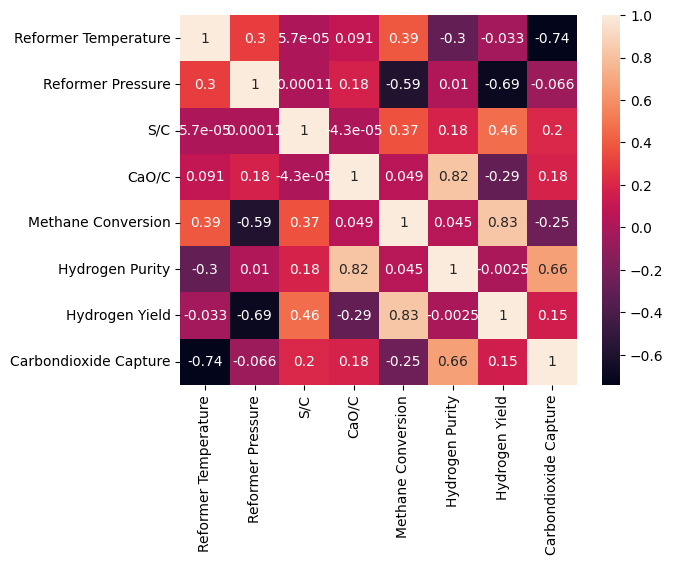

In [ ]:
corr = df.corr()
sns.heatmap(corr, annot = True)

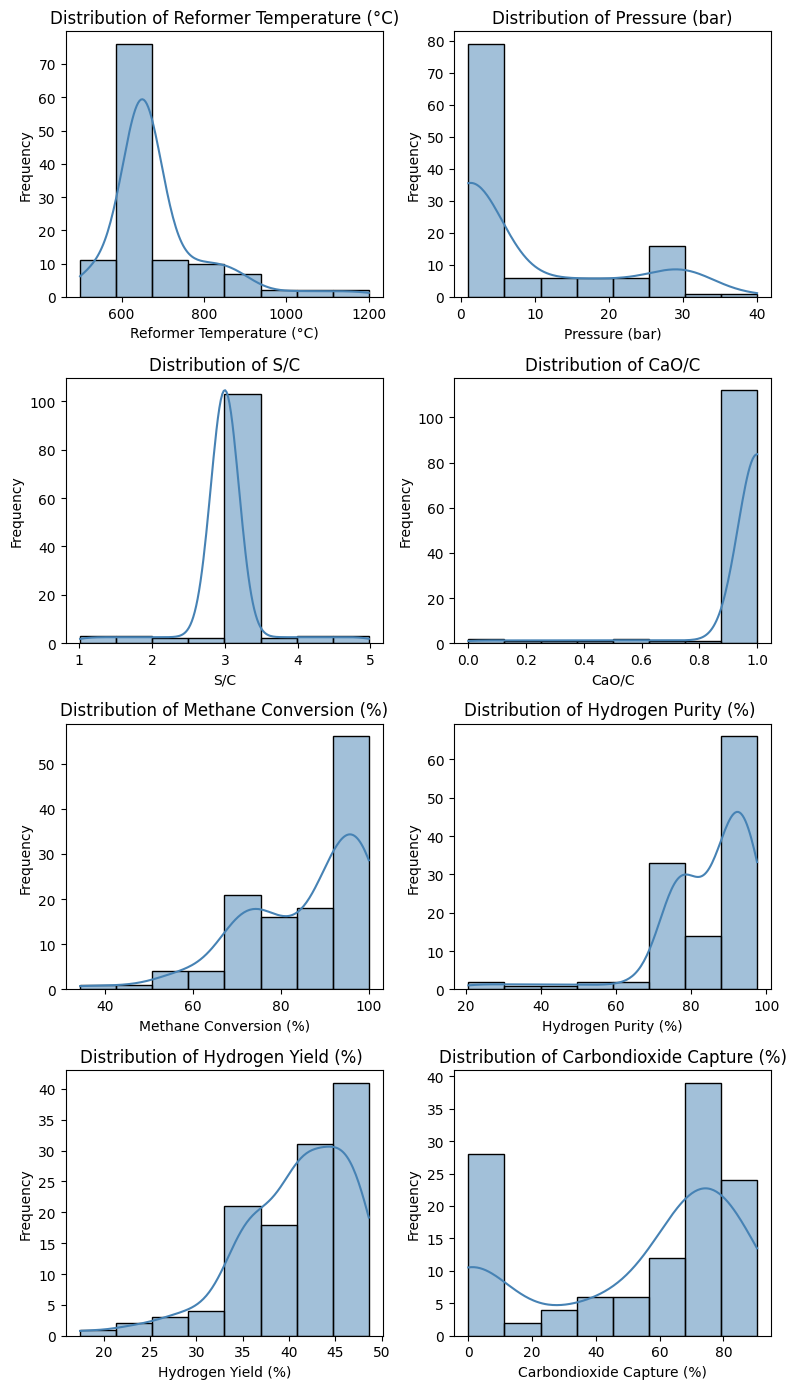

In [ ]:
titles = [
    "Distribution of Reformer Temperature (°C)",
    "Distribution of Pressure (bar)",
    "Distribution of S/C",
    "Distribution of CaO/C",
    "Distribution of Methane Conversion (%)",
    "Distribution of Hydrogen Purity (%) ",
    "Distribution of Hydrogen Yield (%) ",
    "Distribution of Carbondioxide Capture (%)"
]

x_labels = [
    "Reformer Temperature (°C)", "Pressure (bar)", "S/C", "CaO/C",
    "Methane Conversion (%)", "Hydrogen Purity (%)", "Hydrogen Yield (%)", "Carbondioxide Capture (%)"
]

columns = df.columns

fig, axes = plt.subplots(4, 2, figsize= (8, 14))
axes = axes.flatten()
for i, col in enumerate(columns):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=8, color='steelblue')
    axes[i].set_title(titles[i])
    axes[i].set_xlabel(x_labels[i])
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
features = df[['Reformer Temperature', 'Reformer Pressure', 'S/C', 'CaO/C']]
z_scores = np.abs(zscore(features))
outliers = (z_scores > 3).any(axis=1)

In [ ]:
df[outliers]

,Reformer Temperature,Reformer Pressure,S/C,CaO/C,Methane Conversion,Hydrogen Purity,Hydrogen Yield,Carbondioxide Capture
66,650.00,1.01325,1.01,1.0,54.25,71.79,23.92,24.43
67,650.00,1.01325,1.20,1.0,60.25,76.26,27.22,32.10
68,650.00,1.01325,1.40,1.0,66.02,79.94,30.32,39.21
84,650.00,1.01325,4.60,1.0,98.72,94.81,48.32,80.70
85,650.00,1.01325,4.80,1.0,99.05,94.94,48.44,80.89
86,650.00,1.01325,4.98,1.0,99.05,94.93,48.62,80.92
87,650.00,1.01325,3.00,0.0,76.35,20.61,46.99,1.85
88,650.00,1.01325,3.00,0.1,78.40,27.48,47.10,11.59
89,650.00,1.01325,3.00,0.2,80.54,34.71,47.27,21.53
90,650.00,1.01325,3.00,0.3,82.79,42.11,47.45,31.27


In [ ]:
df_clean = df[~outliers]

In [ ]:
scaler = MinMaxScaler()

feature_columns = ['Reformer Temperature', 'Reformer Pressure', 'S/C', 'CaO/C']
target1_names = ['Methane Conversion', 'Hydrogen Yield']
target2_names = ['Hydrogen Purity', 'Carbondioxide Capture']
target_columns = ['Methane Conversion', 'Hydrogen Purity', 'Hydrogen Yield', 'Carbondioxide Capture']

X = df_clean[feature_columns]
y = df_clean[target_columns]

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns = feature_columns, index = df_clean.index)

df_scaled = pd.concat([X_scaled_df, y], axis = 1)


In [ ]:
df_shuffled = df_scaled.sample(frac=1, random_state= 42).reset_index(drop=True)

In [ ]:
df_shuffled

,Reformer Temperature,Reformer Pressure,S/C,CaO/C,Methane Conversion,Hydrogen Purity,Hydrogen Yield,Carbondioxide Capture
0,0.273584,0.000083,0.714286,1.0,96.98,94.21,47.14,78.32
1,0.183262,0.000083,0.500000,1.0,92.21,96.71,45.79,87.49
2,0.073337,0.000083,0.500000,1.0,91.16,97.56,45.38,90.27
3,0.364470,0.743333,0.500000,1.0,69.09,89.41,34.43,67.57
4,0.273584,0.000083,0.285714,1.0,87.71,90.56,41.91,65.71
...,...,...,...,...,...,...,...,...
102,0.273584,0.000083,0.357143,1.0,90.22,91.63,43.36,69.25
103,0.254637,0.000083,0.500000,1.0,93.39,94.43,45.67,78.33
104,0.273584,0.744103,0.500000,1.0,62.12,86.43,31.40,61.72
105,0.273584,0.260513,0.500000,1.0,75.60,92.05,37.70,74.31


In [ ]:
df_shuffled.columns

Index(['Reformer Temperature', 'Reformer Pressure', 'S/C', 'CaO/C',
       'Methane Conversion', 'Hydrogen Purity', 'Hydrogen Yield',
       'Carbondioxide Capture'],
      dtype='object')

In [ ]:
x = df_shuffled.drop (columns= ['Methane Conversion', 'Hydrogen Purity', 'Hydrogen Yield', 'Carbondioxide Capture'])
y1 = df_shuffled[['Methane Conversion', 'Hydrogen Yield']]
y2 = df_shuffled[['Hydrogen Purity', 'Carbondioxide Capture']]


In [ ]:
def initialize_models():
    linear_regressor = LinearRegression()
    svr_regressor = SVR(kernel='rbf', C=1835, gamma=1.527561271042302)
    decision_tree_regressor = DecisionTreeRegressor(max_depth=40, min_samples_split= 2, min_samples_leaf=1, random_state=42)
    random_forest_regressor = RandomForestRegressor(n_estimators=23, max_depth=17, min_samples_split= 3, min_samples_leaf=2, random_state=42)
    catboost_regressor = CatBoostRegressor(iterations=121, eval_metric='RMSE', l2_leaf_reg=1, depth=14, learning_rate=0.03481783197564316, random_state=42)
    lightgbm_regressor = LGBMRegressor(n_estimators=52, eval_metric='RMSE', max_depth=4, num_leaves=4, min_data_in_leaf=1, random_state=42)

    return {
        'Linear Regression': MultiOutputRegressor(linear_regressor),
        'SVM': MultiOutputRegressor(svr_regressor),
        'Decision Tree': MultiOutputRegressor(decision_tree_regressor),
        'Random Forest': MultiOutputRegressor(random_forest_regressor),
        'CatBoost': MultiOutputRegressor(catboost_regressor),
        'LightGBM': MultiOutputRegressor(lightgbm_regressor)
    }


In [ ]:
def initialize_second_models():
    linear_regressor = LinearRegression()
    svr_regressor = SVR(kernel='rbf', C=33746, gamma=6.099200124908606)
    decision_tree_regressor = DecisionTreeRegressor(max_depth=37, min_samples_split= 2, min_samples_leaf=2, random_state=42)
    random_forest_regressor = RandomForestRegressor(n_estimators=39, max_depth=15, min_samples_split= 2, min_samples_leaf=1, random_state=42)
    catboost_regressor = CatBoostRegressor(iterations=119, eval_metric='RMSE', l2_leaf_reg=2, depth=15, learning_rate=0.04231926675102303, random_state=42)
    lightgbm_regressor = LGBMRegressor(n_estimators=58, eval_metric='RMSE', max_depth=4, num_leaves=10, min_data_in_leaf=1, random_state=42)

    return {
        'Linear Regression': MultiOutputRegressor(linear_regressor),
        'SVM': MultiOutputRegressor(svr_regressor),
        'Decision Tree': MultiOutputRegressor(decision_tree_regressor),
        'Random Forest': MultiOutputRegressor(random_forest_regressor),
        'CatBoost': MultiOutputRegressor(catboost_regressor),
        'LightGBM': MultiOutputRegressor(lightgbm_regressor)
    }

In [ ]:
def train_and_evaluate(models, model_name, X_train, y_train, X_test, y_test):

    model = models[model_name]
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred = np.where(y_pred < 0, 0, y_pred)
    y_pred = np.round(y_pred, 2)
    y_test = np.round(y_test, 2)
    return y_pred, y_test

In [ ]:
models = initialize_models()
second_models = initialize_second_models()

model_names = ['Linear Regression', "SVM", "Decision Tree", "Random Forest", "CatBoost", "LightGBM"]

def safe_mape(y_true, y_pred, epsilon=0.08):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mask = np.abs(y_true) > epsilon
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def calculate_metrics_for_single_output(models, model_names, features, target, output_to_predict):
    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

    # all results
    results = []
    for model_name in model_names:
      y_pred, y_test = train_and_evaluate(models, model_name, X_train, y_train, X_test, y_test)

      y_pred_ = pd.DataFrame(y_pred, columns=y_test.columns)[output_to_predict]
      y_test_ = y_test[output_to_predict]

      # Calculating metrics
      r_squared = r2_score(y_test_, y_pred_)
      mse = mean_squared_error(y_test_, y_pred_)
      rmse = np.sqrt(mse)
      mae = mean_absolute_error(y_test_, y_pred_)
      # Calculate MAPE, handling division by zero and small values
      mape = safe_mape(y_test_, y_pred_)

      # Append the results
      results.append({
          'Model': model_name,
          'R-Squared': r_squared,
          'MSE': mse,
          'RMSE': rmse,
          'MAE': mae,
          'MAPE': mape
      })

    # Creating the DataFrame from the results list
    metrics_df = pd.DataFrame(results)

    return metrics_df.round(3), y_test_, y_pred_


# EVALUATION OF MODEL PERFORMANCE

In [ ]:
calculate_metrics_for_single_output(models=models, model_names=model_names, features=x, target=y1, output_to_predict= 'Methane Conversion')

0:	learn: 13.7114144	total: 47.2ms	remaining: 5.67s
1:	learn: 13.3859840	total: 67ms	remaining: 3.99s
2:	learn: 13.0722507	total: 70.2ms	remaining: 2.76s
3:	learn: 12.7393663	total: 71.4ms	remaining: 2.09s
4:	learn: 12.4481618	total: 71.7ms	remaining: 1.66s
5:	learn: 12.1313663	total: 87ms	remaining: 1.67s
6:	learn: 11.8108733	total: 99.1ms	remaining: 1.61s
7:	learn: 11.5047853	total: 115ms	remaining: 1.62s
8:	learn: 11.2403878	total: 166ms	remaining: 2.06s
9:	learn: 11.0589463	total: 168ms	remaining: 1.86s
10:	learn: 10.7964662	total: 173ms	remaining: 1.73s
11:	learn: 10.5292894	total: 223ms	remaining: 2.02s
12:	learn: 10.2666959	total: 266ms	remaining: 2.21s
13:	learn: 10.0249566	total: 267ms	remaining: 2.04s
14:	learn: 9.8244231	total: 267ms	remaining: 1.89s
15:	learn: 9.5677777	total: 279ms	remaining: 1.83s
16:	learn: 9.3307759	total: 280ms	remaining: 1.71s
17:	learn: 9.1078831	total: 280ms	remaining: 1.6s
18:	learn: 8.9255382	total: 281ms	remaining: 1.51s
19:	learn: 8.6972595	tota

(               Model  R-Squared     MSE   RMSE    MAE   MAPE
 0  Linear Regression      0.864  19.221  4.384  3.334  3.920
 1                SVM      0.993   0.947  0.973  0.655  0.798
 2      Decision Tree      0.967   4.703  2.169  1.426  1.735
 3      Random Forest      0.982   2.478  1.574  0.996  1.204
 4           CatBoost      0.977   3.226  1.796  1.285  1.549
 5           LightGBM      0.944   7.853  2.802  1.830  2.094,
 76     93.77
 10     98.07
 4      87.71
 99     89.83
 70     92.29
 66     58.83
 30     73.93
 45     99.97
 94     98.62
 11     79.45
 78     78.40
 47     86.23
 0      96.98
 79     93.20
 18     68.39
 105    75.60
 55     69.27
 77     71.16
 65     84.55
 42     99.97
 12     90.76
 36     99.66
 Name: Methane Conversion, dtype: float64,
 0     92.29
 1     95.62
 2     83.24
 3     92.29
 4     83.24
 5     60.71
 6     73.54
 7     99.10
 8     98.35
 9     80.20
 10    80.20
 11    85.67
 12    95.62
 13    86.84
 14    69.41
 15    76.17
 16   

In [ ]:

calculate_metrics_for_single_output(models=models, model_names=model_names, features=x, target=y1, output_to_predict= 'Hydrogen Yield')

0:	learn: 13.7114144	total: 507us	remaining: 60.9ms
1:	learn: 13.3859840	total: 9.53ms	remaining: 567ms
2:	learn: 13.0722507	total: 11ms	remaining: 433ms
3:	learn: 12.7393663	total: 11.8ms	remaining: 346ms
4:	learn: 12.4481618	total: 12.1ms	remaining: 281ms
5:	learn: 12.1313663	total: 16.8ms	remaining: 322ms
6:	learn: 11.8108733	total: 22.5ms	remaining: 366ms
7:	learn: 11.5047853	total: 27.5ms	remaining: 388ms
8:	learn: 11.2403878	total: 48ms	remaining: 597ms
9:	learn: 11.0589463	total: 48.2ms	remaining: 535ms
10:	learn: 10.7964662	total: 50.4ms	remaining: 504ms
11:	learn: 10.5292894	total: 66.4ms	remaining: 604ms
12:	learn: 10.2666959	total: 83.9ms	remaining: 697ms
13:	learn: 10.0249566	total: 84.3ms	remaining: 644ms
14:	learn: 9.8244231	total: 84.6ms	remaining: 598ms
15:	learn: 9.5677777	total: 88.8ms	remaining: 583ms
16:	learn: 9.3307759	total: 89.5ms	remaining: 547ms
17:	learn: 9.1078831	total: 89.7ms	remaining: 513ms
18:	learn: 8.9255382	total: 89.9ms	remaining: 483ms
19:	learn: 8

(               Model  R-Squared    MSE   RMSE    MAE   MAPE
 0  Linear Regression      0.826  3.801  1.950  1.539  3.747
 1                SVM      0.988  0.264  0.514  0.330  0.841
 2      Decision Tree      0.953  1.015  1.007  0.717  1.849
 3      Random Forest      0.976  0.522  0.722  0.435  1.100
 4           CatBoost      0.967  0.716  0.846  0.648  1.632
 5           LightGBM      0.903  2.105  1.451  0.903  2.221,
 76     45.45
 10     47.76
 4      41.91
 99     48.15
 70     44.44
 66     29.53
 30     37.21
 45     41.57
 94     42.06
 11     39.59
 78     39.07
 47     42.85
 0      47.14
 79     38.32
 18     34.08
 105    37.70
 55     34.61
 77     35.53
 65     40.20
 42     41.51
 12     45.39
 36     42.00
 Name: Hydrogen Yield, dtype: float64,
 0     45.45
 1     46.48
 2     39.50
 3     47.82
 4     39.50
 5     30.61
 6     36.66
 7     42.04
 8     42.04
 9     40.32
 10    40.32
 11    42.21
 12    46.48
 13    35.43
 14    34.60
 15    38.20
 16    34.60
 17 

In [ ]:
calculate_metrics_for_single_output(models=second_models, model_names=model_names, features=x, target=y2, output_to_predict= 'Hydrogen Purity')

0:	learn: 8.2982593	total: 1.98ms	remaining: 234ms
1:	learn: 8.0711373	total: 8.78ms	remaining: 514ms
2:	learn: 7.8729854	total: 9.49ms	remaining: 367ms
3:	learn: 7.7138068	total: 9.64ms	remaining: 277ms
4:	learn: 7.5189825	total: 10.3ms	remaining: 235ms
5:	learn: 7.3590436	total: 10.7ms	remaining: 202ms
6:	learn: 7.2118771	total: 10.9ms	remaining: 174ms
7:	learn: 7.0231780	total: 11.1ms	remaining: 154ms
8:	learn: 6.8602111	total: 11.3ms	remaining: 138ms
9:	learn: 6.7084016	total: 12.5ms	remaining: 136ms
10:	learn: 6.5672175	total: 23.9ms	remaining: 235ms
11:	learn: 6.4243939	total: 26.2ms	remaining: 233ms
12:	learn: 6.2724903	total: 26.6ms	remaining: 217ms
13:	learn: 6.1207513	total: 26.8ms	remaining: 201ms
14:	learn: 5.9973000	total: 27ms	remaining: 187ms
15:	learn: 5.8849343	total: 27.2ms	remaining: 175ms
16:	learn: 5.7649485	total: 27.5ms	remaining: 165ms
17:	learn: 5.6468392	total: 68.5ms	remaining: 384ms
18:	learn: 5.5193011	total: 101ms	remaining: 533ms
19:	learn: 5.4226501	tota

(               Model  R-Squared     MSE   RMSE    MAE   MAPE
 0  Linear Regression      0.812  12.825  3.581  3.070  3.604
 1                SVM      0.979   1.410  1.187  0.735  0.931
 2      Decision Tree      0.938   4.205  2.051  1.101  1.216
 3      Random Forest      0.949   3.493  1.869  1.014  1.156
 4           CatBoost      0.974   1.775  1.332  1.012  1.185
 5           LightGBM      0.904   6.540  2.557  1.239  1.556,
 76     93.27
 10     94.57
 4      90.56
 99     65.94
 70     92.48
 66     84.69
 30     91.65
 45     76.87
 94     77.16
 11     93.20
 78     92.90
 47     94.42
 0      94.21
 79     75.10
 18     89.17
 105    92.05
 55     89.75
 77     90.47
 65     89.27
 42     76.80
 12     97.56
 36     77.01
 Name: Hydrogen Purity, dtype: float64,
 0     90.37
 1     93.90
 2     87.87
 3     76.06
 4     87.87
 5     85.14
 6     91.34
 7     77.08
 8     77.17
 9     93.31
 10    93.31
 11    93.70
 12    93.90
 13    74.68
 14    89.94
 15    92.21
 16    89

In [ ]:
calculate_metrics_for_single_output(models=second_models, model_names=model_names, features=x, target=y2, output_to_predict= 'Carbondioxide Capture')

0:	learn: 8.2982593	total: 1.44ms	remaining: 170ms
1:	learn: 8.0711373	total: 7.07ms	remaining: 414ms
2:	learn: 7.8729854	total: 8.53ms	remaining: 330ms
3:	learn: 7.7138068	total: 8.71ms	remaining: 250ms
4:	learn: 7.5189825	total: 9.99ms	remaining: 228ms
5:	learn: 7.3590436	total: 10.9ms	remaining: 205ms
6:	learn: 7.2118771	total: 11.2ms	remaining: 179ms
7:	learn: 7.0231780	total: 11.4ms	remaining: 158ms
8:	learn: 6.8602111	total: 11.8ms	remaining: 145ms
9:	learn: 6.7084016	total: 13.1ms	remaining: 142ms
10:	learn: 6.5672175	total: 23.3ms	remaining: 229ms
11:	learn: 6.4243939	total: 26.5ms	remaining: 236ms
12:	learn: 6.2724903	total: 27.3ms	remaining: 223ms
13:	learn: 6.1207513	total: 27.6ms	remaining: 207ms
14:	learn: 5.9973000	total: 27.9ms	remaining: 193ms
15:	learn: 5.8849343	total: 28.3ms	remaining: 182ms
16:	learn: 5.7649485	total: 28.5ms	remaining: 171ms
17:	learn: 5.6468392	total: 75.1ms	remaining: 422ms
18:	learn: 5.5193011	total: 107ms	remaining: 563ms
19:	learn: 5.4226501	to

(               Model  R-Squared      MSE    RMSE     MAE    MAPE
 0  Linear Regression      0.779  213.459  14.610  11.514  12.785
 1                SVM      0.988   11.840   3.441   1.761   1.811
 2      Decision Tree      0.991    8.545   2.923   1.330   2.566
 3      Random Forest      0.996    4.241   2.059   1.281   1.911
 4           CatBoost      0.994    5.324   2.307   1.885   2.723
 5           LightGBM      0.983   16.627   4.078   2.146   3.954,
 76     74.08
 10     79.65
 4      65.71
 99     60.70
 70     71.82
 66     58.58
 30     73.16
 45      0.01
 94      0.01
 11     77.28
 78     76.44
 47     80.41
 0      78.32
 79      0.08
 18     67.83
 105    74.31
 55     68.88
 77     70.59
 65     61.70
 42      0.01
 12     90.55
 36      0.01
 Name: Carbondioxide Capture, dtype: float64,
 0     76.37
 1     77.16
 2     59.64
 3     73.18
 4     59.64
 5     59.30
 6     72.57
 7      0.11
 8      0.60
 9     77.63
 10    77.63
 11    78.71
 12    77.16
 13     0.71
 

In [ ]:
def plot_actual_vs_predicted_test(ax, y_actual, y_pred, title, r2_score, rmse, label):
    ax.scatter(y_actual, y_pred, color='green', s=30)
    ax.plot([min(y_actual), max(y_actual)], [min(y_actual), max(y_actual)], color='red')
    ax.set_xlabel('Actual Values (%)')
    ax.set_ylabel('Predicted Values (%)')
    ax.set_title(title)
    textstr = f'R2 score: {r2_score:.4f}\nRMSE: {rmse:.2f}'
    ax.text(0.05, 0.95, textstr,
            transform=ax.transAxes,
            verticalalignment='top',
            horizontalalignment='left',
            fontsize=10,
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
    ax.text(0.95, 0.05, label,
        transform=ax.transAxes,
        verticalalignment='bottom',
        horizontalalignment='right',
        fontsize=14)

In [ ]:
def plot_actual_vs_predicted_train(ax, y_actual, y_pred, title, r2_score, rmse, label):
    ax.scatter(y_actual, y_pred, color='purple', s=30)
    ax.plot([min(y_actual), max(y_actual)], [min(y_actual), max(y_actual)], color='red')
    ax.set_xlabel('Actual Values (%)')
    ax.set_ylabel('Predicted Values (%)')
    ax.set_title(f"{label}) {title}")
    textstr = f'R2 score: {r2_score:.4f}\nRMSE: {rmse:.2f}'
    ax.text(0.05, 0.95, textstr,
            transform=ax.transAxes,
            verticalalignment='top',
            horizontalalignment='left',
            fontsize=10,
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
    ax.text(0.95, 0.05, label,
        transform=ax.transAxes,
        verticalalignment='bottom',
        horizontalalignment='right',
        fontsize=14)

In [ ]:
subplot_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

def plots_for_actual_vs_predicted(models, model_names, features, target, output_to_predict):
    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

    num_models = len(models)
    num_rows = num_models // 2
    fig, axs = plt.subplots(num_rows, 2, figsize=(15, 15))
    axs = axs.ravel()


    for i, model_name in enumerate(model_names):
        y_pred, y_test = train_and_evaluate(models, model_name, X_train, y_train, X_test, y_test)
        y_pred_ = pd.DataFrame(y_pred, columns=y_test.columns)[output_to_predict]
        y_test_ = y_test[output_to_predict]

        r2 = r2_score(y_test_, y_pred_)
        rmse = np.sqrt(mean_squared_error(y_test_, y_pred_))
        plot_actual_vs_predicted_test(axs[i], y_test_, y_pred_, f"{model_name}--{output_to_predict} (%)", r2, rmse, subplot_labels[i])

    fig.tight_layout()
    plt.show()

def plots_for_actual_vs_predicted_train(models, model_names, features, target, output_to_predict):
    # Split data into training and testing sets
    X_train, _, y_train, _ = train_test_split(features, target, test_size=0.2, random_state=42)

    num_models = len(models)
    num_rows = num_models // 2
    fig, axs = plt.subplots(num_rows, 2, figsize=(15, 15))
    axs = axs.ravel()

    for i, model_name in enumerate(model_names):
        y_pred, y_test = train_and_evaluate(models, model_name, X_train, y_train, X_train, y_train)
        y_pred_ = pd.DataFrame(y_pred, columns=y_test.columns)[output_to_predict]
        y_test_ = y_test[output_to_predict]

        r2 = r2_score(y_test_, y_pred_)
        rmse = np.sqrt(mean_squared_error(y_test_, y_pred_))
        plot_actual_vs_predicted_train(axs[i], y_test_, y_pred_, f"{model_name}--{output_to_predict} (%)", r2, rmse, subplot_labels[i])

    fig.tight_layout()
    plt.show()

# TRAIN AND TEST PLOTS FOR METHANE CONVERSION

0:	learn: 13.7114144	total: 464us	remaining: 55.8ms
1:	learn: 13.3859840	total: 6.74ms	remaining: 401ms
2:	learn: 13.0722507	total: 7.7ms	remaining: 303ms
3:	learn: 12.7393663	total: 8.27ms	remaining: 242ms
4:	learn: 12.4481618	total: 8.44ms	remaining: 196ms
5:	learn: 12.1313663	total: 12ms	remaining: 229ms
6:	learn: 11.8108733	total: 15.3ms	remaining: 250ms
7:	learn: 11.5047853	total: 19.7ms	remaining: 278ms
8:	learn: 11.2403878	total: 37.6ms	remaining: 468ms
9:	learn: 11.0589463	total: 37.8ms	remaining: 419ms
10:	learn: 10.7964662	total: 39.5ms	remaining: 395ms
11:	learn: 10.5292894	total: 52.4ms	remaining: 476ms
12:	learn: 10.2666959	total: 65.1ms	remaining: 541ms
13:	learn: 10.0249566	total: 65.4ms	remaining: 500ms
14:	learn: 9.8244231	total: 65.7ms	remaining: 464ms
15:	learn: 9.5677777	total: 70.7ms	remaining: 464ms
16:	learn: 9.3307759	total: 71.3ms	remaining: 436ms
17:	learn: 9.1078831	total: 71.4ms	remaining: 409ms
18:	learn: 8.9255382	total: 71.6ms	remaining: 384ms
19:	learn: 

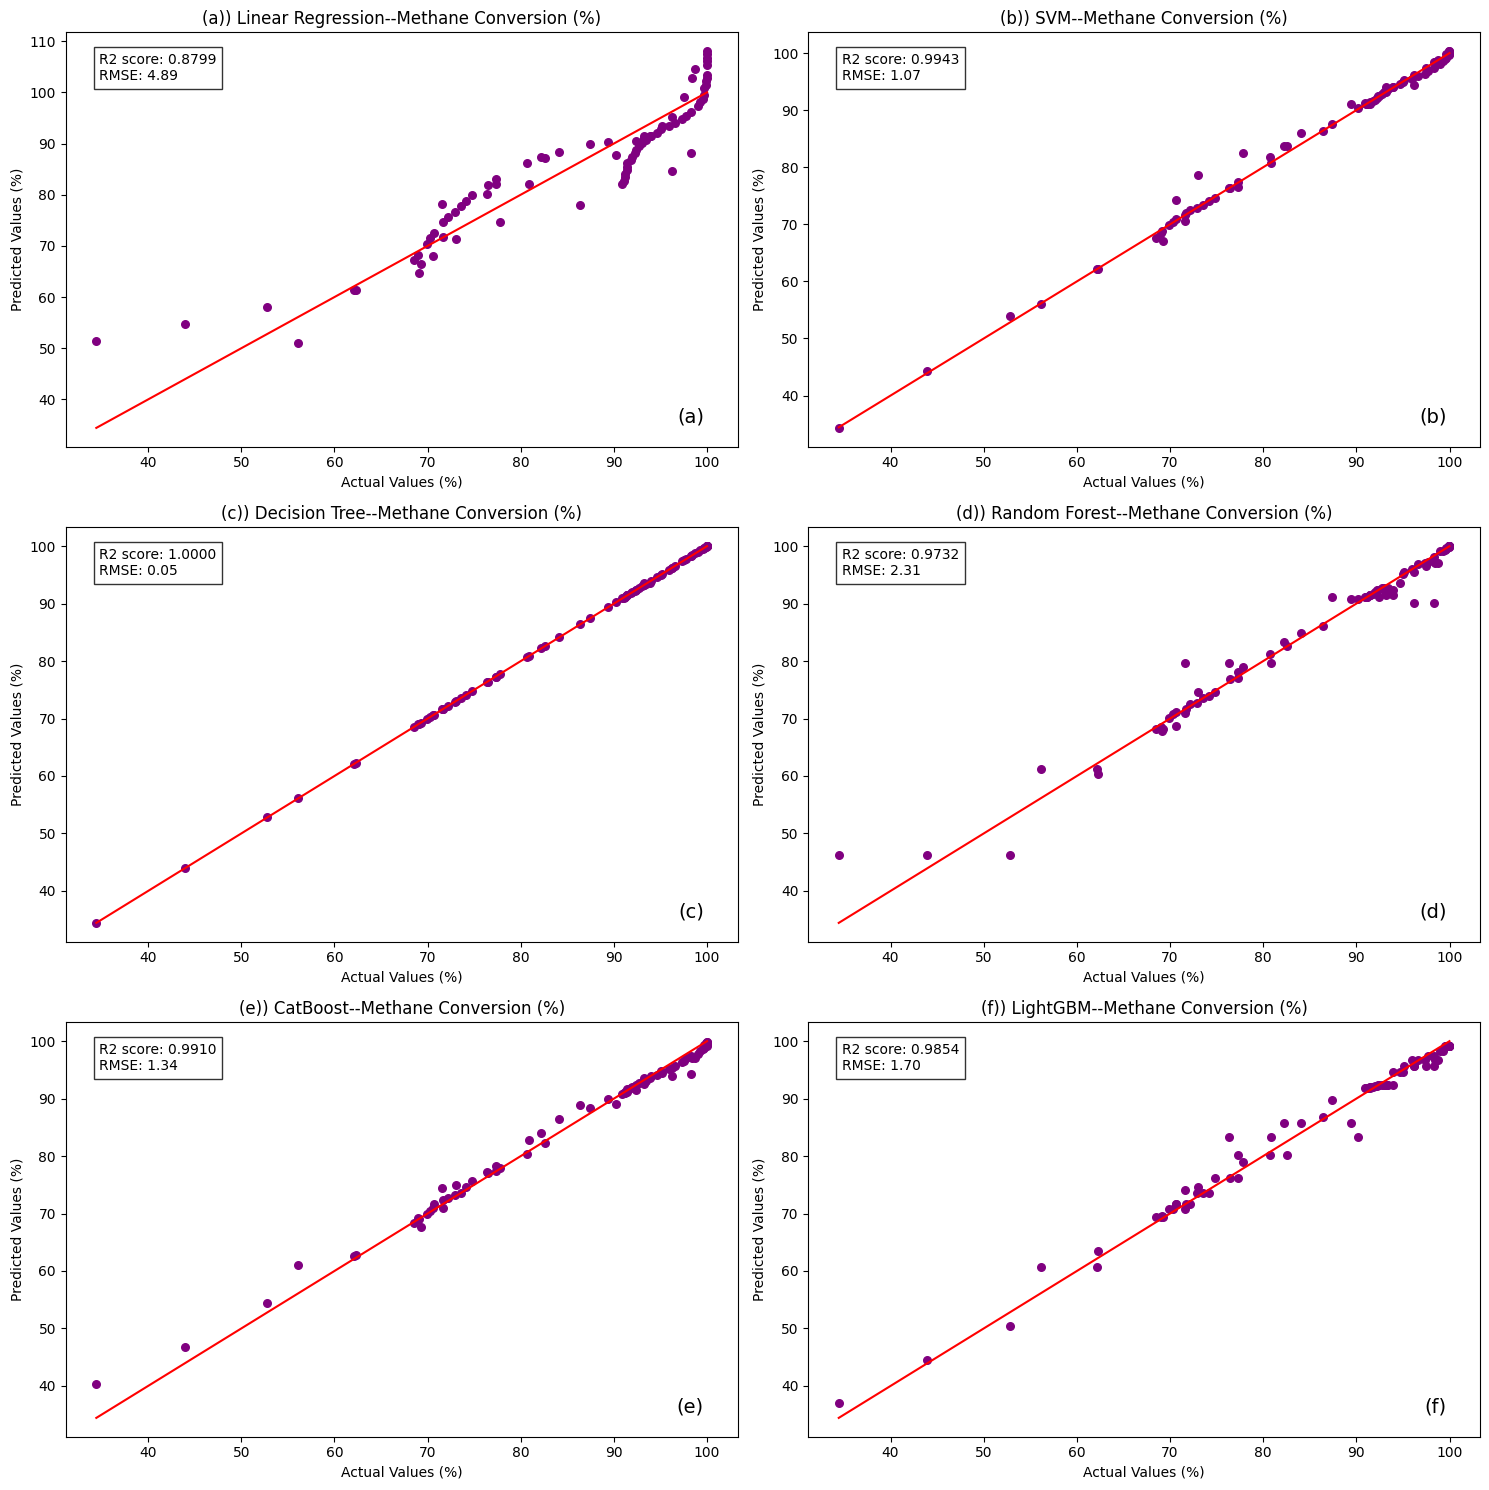

In [ ]:
plots_for_actual_vs_predicted_train(models=models, model_names=model_names, features=x, target=y1, output_to_predict='Methane Conversion')

0:	learn: 13.7114144	total: 440us	remaining: 52.9ms
1:	learn: 13.3859840	total: 4.43ms	remaining: 264ms
2:	learn: 13.0722507	total: 5.41ms	remaining: 213ms
3:	learn: 12.7393663	total: 5.97ms	remaining: 175ms
4:	learn: 12.4481618	total: 6.15ms	remaining: 143ms
5:	learn: 12.1313663	total: 9.54ms	remaining: 183ms
6:	learn: 11.8108733	total: 12.8ms	remaining: 208ms
7:	learn: 11.5047853	total: 15.9ms	remaining: 225ms
8:	learn: 11.2403878	total: 29.6ms	remaining: 368ms
9:	learn: 11.0589463	total: 29.7ms	remaining: 330ms
10:	learn: 10.7964662	total: 31.3ms	remaining: 313ms
11:	learn: 10.5292894	total: 43.5ms	remaining: 395ms
12:	learn: 10.2666959	total: 57.4ms	remaining: 477ms
13:	learn: 10.0249566	total: 57.7ms	remaining: 441ms
14:	learn: 9.8244231	total: 57.9ms	remaining: 409ms
15:	learn: 9.5677777	total: 61.4ms	remaining: 403ms
16:	learn: 9.3307759	total: 61.9ms	remaining: 379ms
17:	learn: 9.1078831	total: 62.1ms	remaining: 355ms
18:	learn: 8.9255382	total: 62.2ms	remaining: 334ms
19:	lear

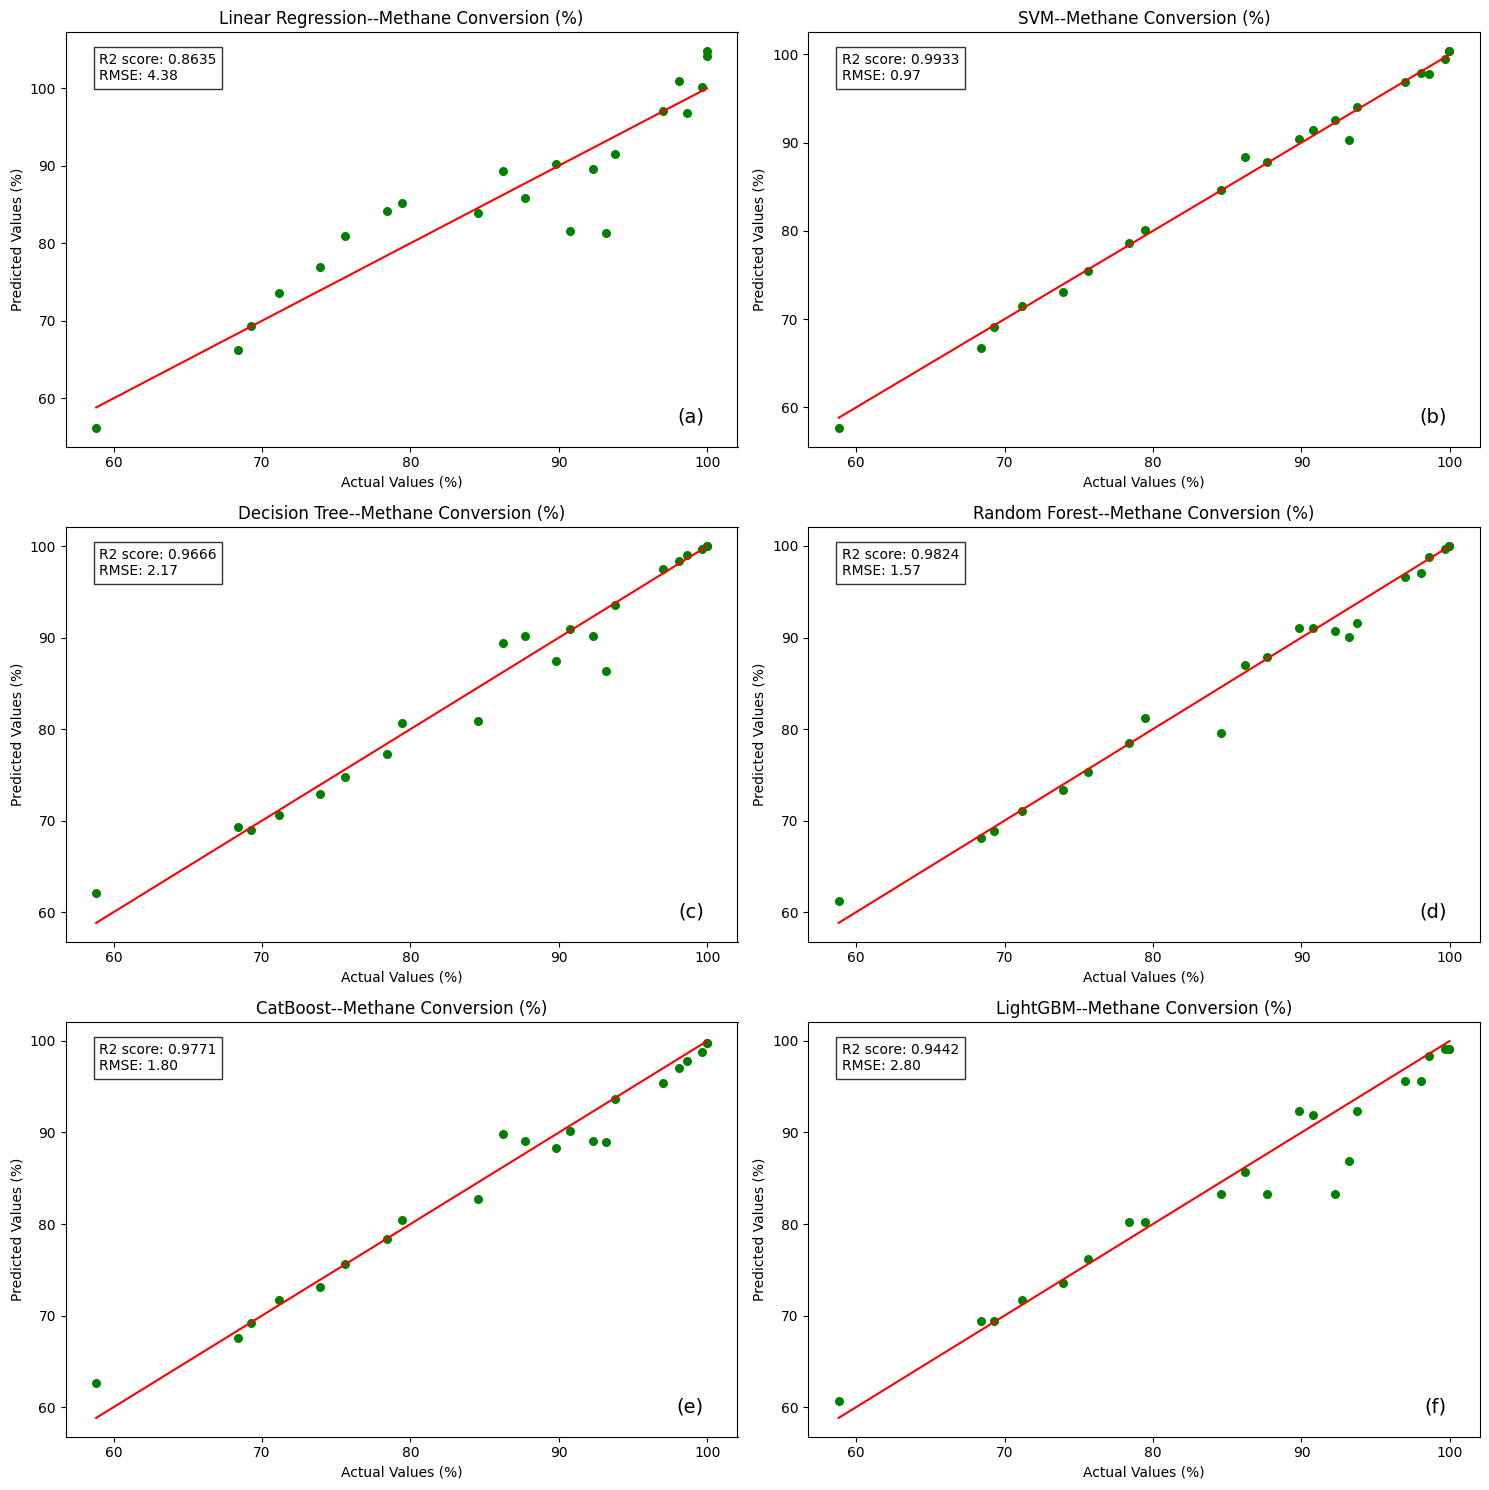

In [ ]:
plots_for_actual_vs_predicted(models=models, model_names=model_names, features=x, target=y1, output_to_predict='Methane Conversion')

# TRAIN AND TEST PLOTS FOR HYDROGEN YIELD

0:	learn: 13.7114144	total: 441us	remaining: 53ms
1:	learn: 13.3859840	total: 4.17ms	remaining: 248ms
2:	learn: 13.0722507	total: 5.22ms	remaining: 205ms
3:	learn: 12.7393663	total: 5.81ms	remaining: 170ms
4:	learn: 12.4481618	total: 6.02ms	remaining: 140ms
5:	learn: 12.1313663	total: 9.7ms	remaining: 186ms
6:	learn: 11.8108733	total: 13.3ms	remaining: 216ms
7:	learn: 11.5047853	total: 16.6ms	remaining: 235ms
8:	learn: 11.2403878	total: 30.4ms	remaining: 378ms
9:	learn: 11.0589463	total: 30.5ms	remaining: 338ms
10:	learn: 10.7964662	total: 32.1ms	remaining: 321ms
11:	learn: 10.5292894	total: 45.1ms	remaining: 410ms
12:	learn: 10.2666959	total: 58.1ms	remaining: 482ms
13:	learn: 10.0249566	total: 58.3ms	remaining: 446ms
14:	learn: 9.8244231	total: 58.6ms	remaining: 414ms
15:	learn: 9.5677777	total: 61.9ms	remaining: 406ms
16:	learn: 9.3307759	total: 62.5ms	remaining: 382ms
17:	learn: 9.1078831	total: 62.7ms	remaining: 359ms
18:	learn: 8.9255382	total: 62.8ms	remaining: 337ms
19:	learn: 

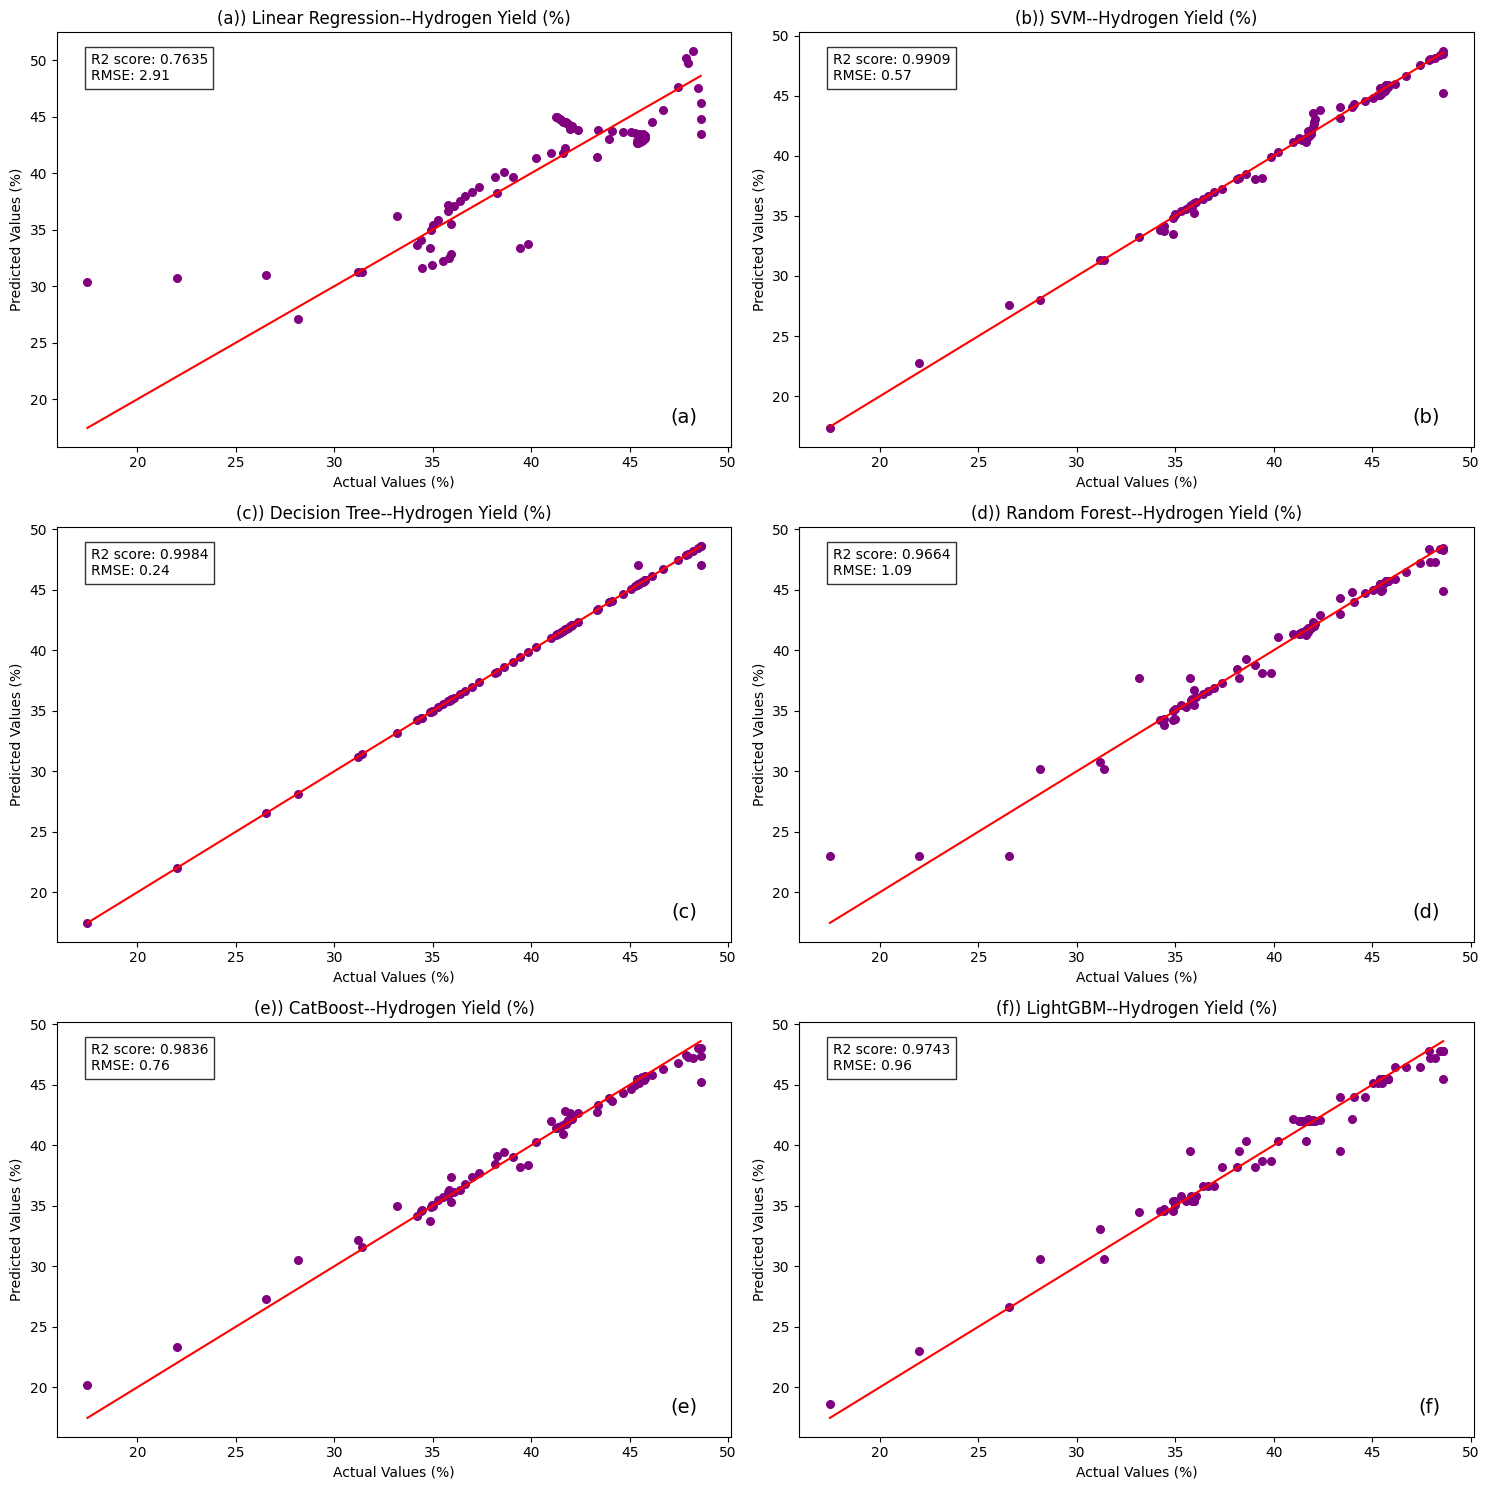

In [ ]:
plots_for_actual_vs_predicted_train(models=models, model_names=model_names, features=x, target=y1, output_to_predict='Hydrogen Yield')

0:	learn: 13.7114144	total: 441us	remaining: 53ms
1:	learn: 13.3859840	total: 4.47ms	remaining: 266ms
2:	learn: 13.0722507	total: 5.44ms	remaining: 214ms
3:	learn: 12.7393663	total: 6.01ms	remaining: 176ms
4:	learn: 12.4481618	total: 6.19ms	remaining: 144ms
5:	learn: 12.1313663	total: 9.57ms	remaining: 184ms
6:	learn: 11.8108733	total: 12.8ms	remaining: 209ms
7:	learn: 11.5047853	total: 16.2ms	remaining: 229ms
8:	learn: 11.2403878	total: 31.5ms	remaining: 392ms
9:	learn: 11.0589463	total: 31.6ms	remaining: 351ms
10:	learn: 10.7964662	total: 33.4ms	remaining: 334ms
11:	learn: 10.5292894	total: 45.9ms	remaining: 417ms
12:	learn: 10.2666959	total: 58.6ms	remaining: 487ms
13:	learn: 10.0249566	total: 58.9ms	remaining: 450ms
14:	learn: 9.8244231	total: 59.1ms	remaining: 418ms
15:	learn: 9.5677777	total: 62.4ms	remaining: 410ms
16:	learn: 9.3307759	total: 63ms	remaining: 385ms
17:	learn: 9.1078831	total: 63.1ms	remaining: 361ms
18:	learn: 8.9255382	total: 63.3ms	remaining: 340ms
19:	learn: 8

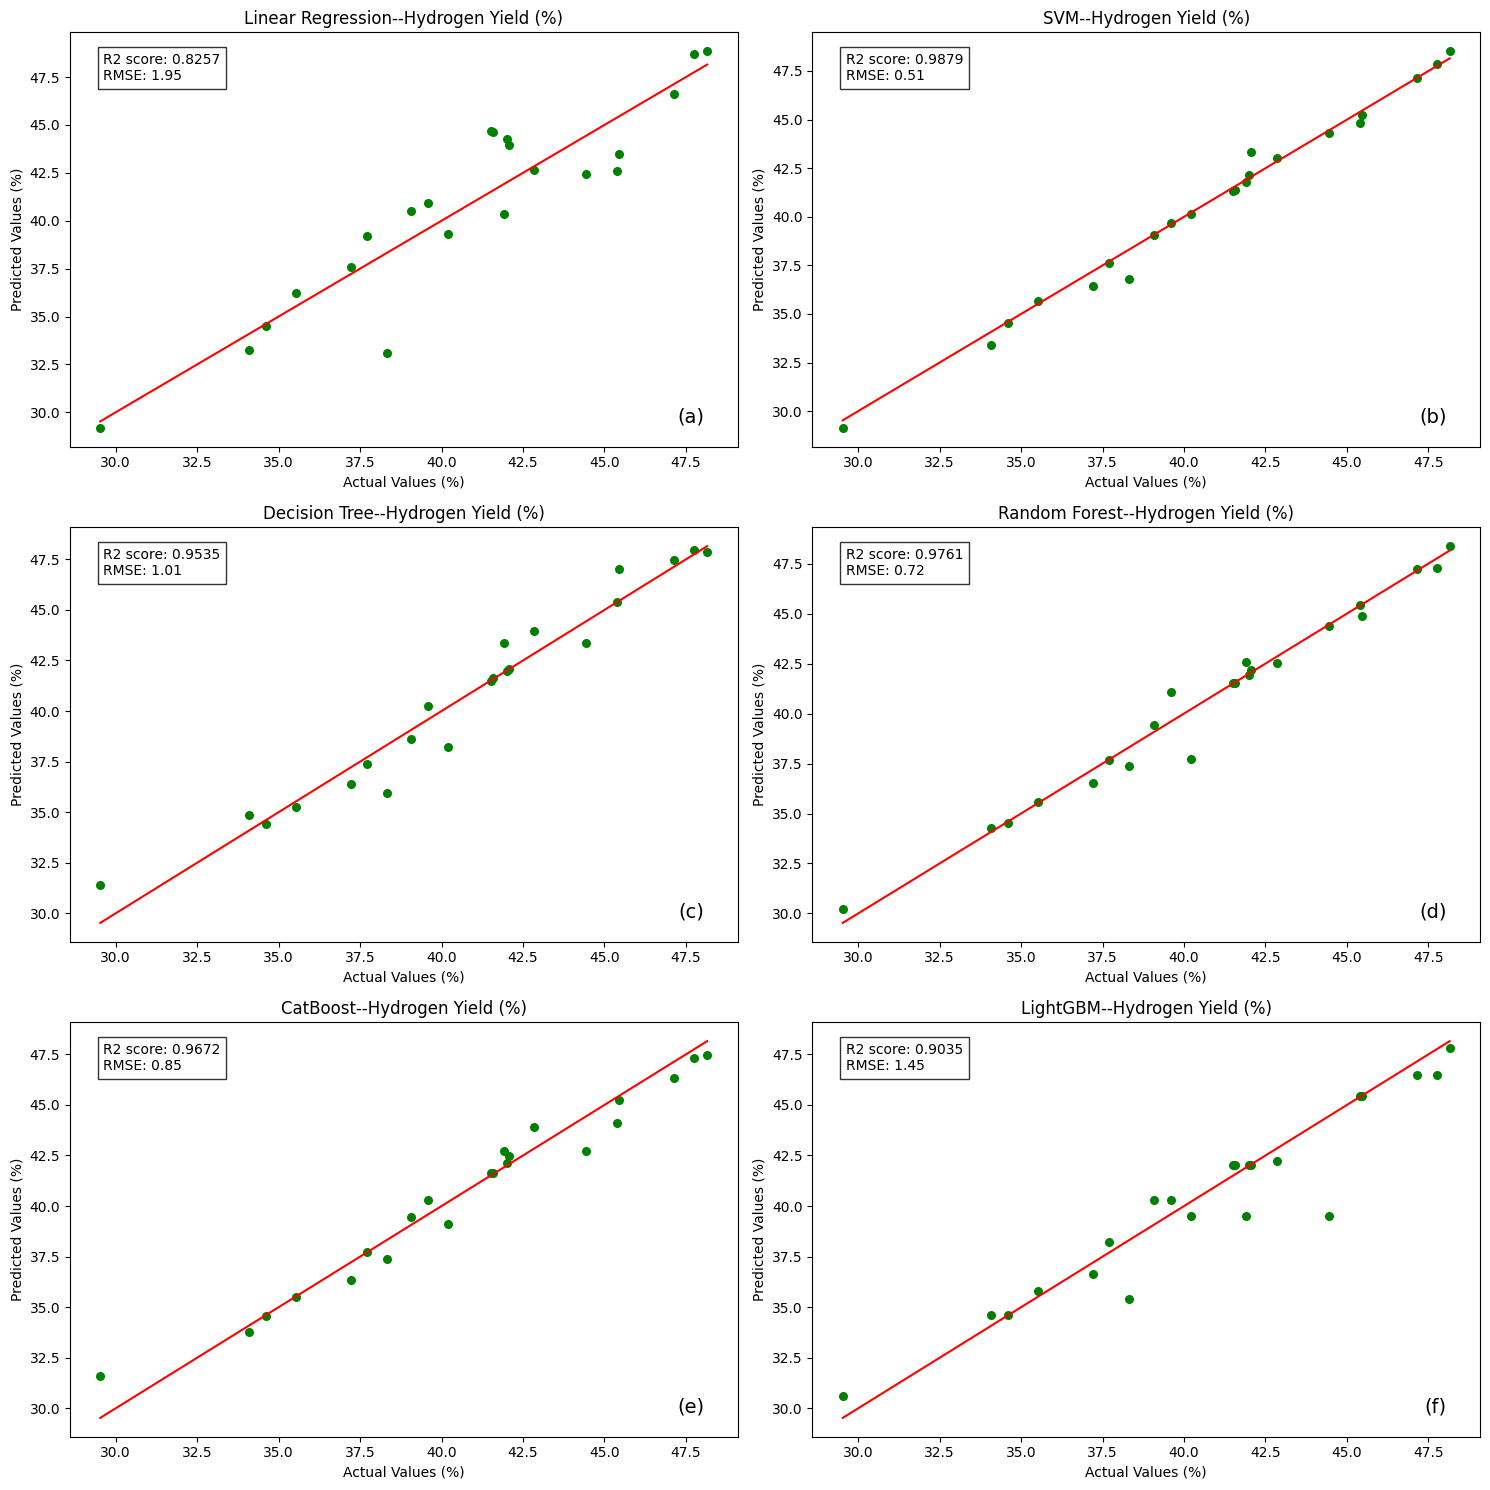

In [ ]:
plots_for_actual_vs_predicted(models=models, model_names=model_names, features=x, target=y1, output_to_predict='Hydrogen Yield')

# TRAIN AND TEST PLOTS FOR HYDROGEN PURITY

0:	learn: 8.2982593	total: 1.23ms	remaining: 146ms
1:	learn: 8.0711373	total: 8.42ms	remaining: 493ms
2:	learn: 7.8729854	total: 10.8ms	remaining: 419ms
3:	learn: 7.7138068	total: 11ms	remaining: 316ms
4:	learn: 7.5189825	total: 12.4ms	remaining: 282ms
5:	learn: 7.3590436	total: 15ms	remaining: 283ms
6:	learn: 7.2118771	total: 15.3ms	remaining: 246ms
7:	learn: 7.0231780	total: 15.6ms	remaining: 217ms
8:	learn: 6.8602111	total: 16.1ms	remaining: 196ms
9:	learn: 6.7084016	total: 17.9ms	remaining: 196ms
10:	learn: 6.5672175	total: 31.4ms	remaining: 308ms
11:	learn: 6.4243939	total: 33.4ms	remaining: 298ms
12:	learn: 6.2724903	total: 33.9ms	remaining: 276ms
13:	learn: 6.1207513	total: 34.1ms	remaining: 256ms
14:	learn: 5.9973000	total: 34.3ms	remaining: 237ms
15:	learn: 5.8849343	total: 34.5ms	remaining: 222ms
16:	learn: 5.7649485	total: 34.7ms	remaining: 208ms
17:	learn: 5.6468392	total: 69.1ms	remaining: 388ms
18:	learn: 5.5193011	total: 97.8ms	remaining: 515ms
19:	learn: 5.4226501	total

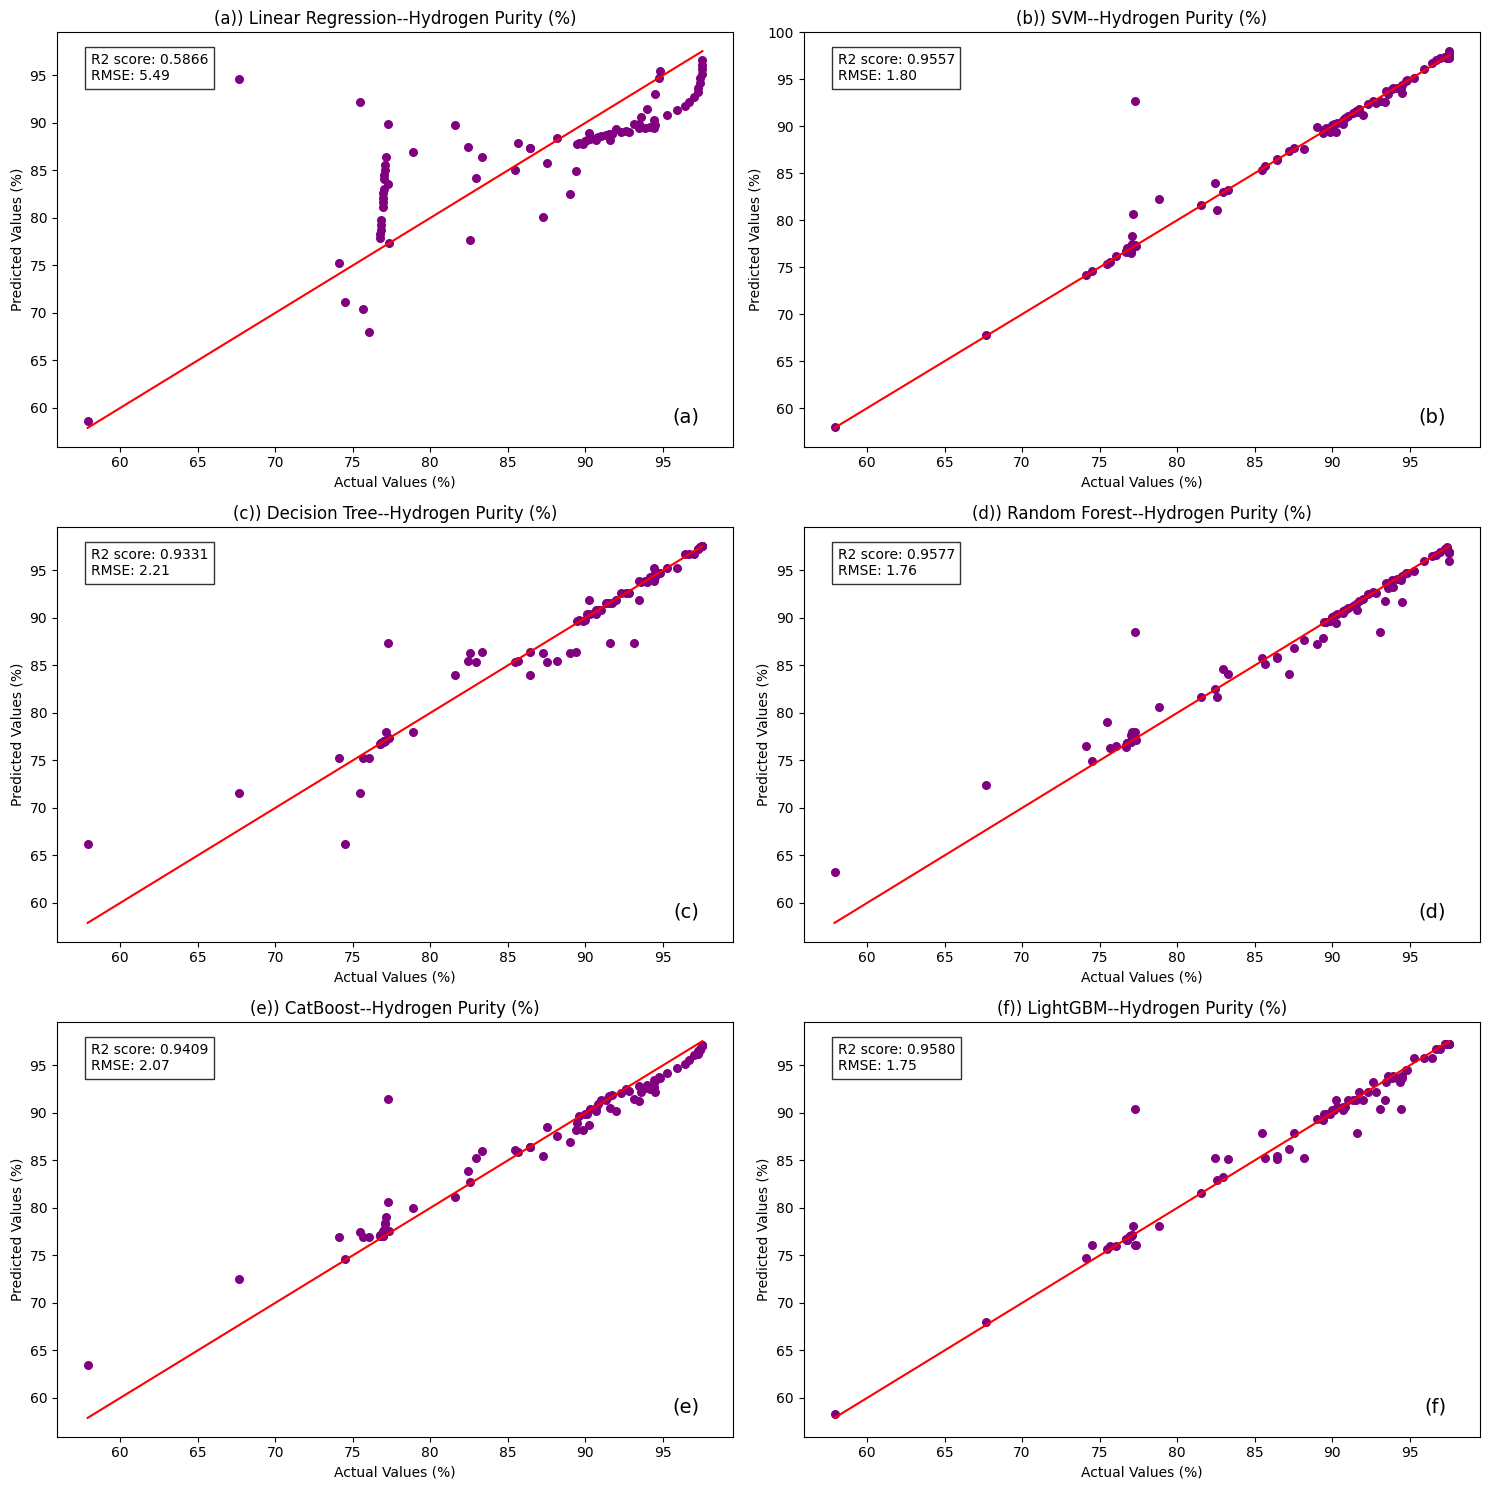

In [ ]:
plots_for_actual_vs_predicted_train(models=second_models, model_names=model_names, features=x, target=y2, output_to_predict='Hydrogen Purity')

0:	learn: 8.2982593	total: 3.54ms	remaining: 418ms
1:	learn: 8.0711373	total: 15ms	remaining: 875ms
2:	learn: 7.8729854	total: 16ms	remaining: 620ms
3:	learn: 7.7138068	total: 16.2ms	remaining: 465ms
4:	learn: 7.5189825	total: 17.2ms	remaining: 391ms
5:	learn: 7.3590436	total: 17.9ms	remaining: 336ms
6:	learn: 7.2118771	total: 18.1ms	remaining: 289ms
7:	learn: 7.0231780	total: 18.3ms	remaining: 254ms
8:	learn: 6.8602111	total: 18.6ms	remaining: 227ms
9:	learn: 6.7084016	total: 24.6ms	remaining: 268ms
10:	learn: 6.5672175	total: 40.2ms	remaining: 395ms
11:	learn: 6.4243939	total: 47.2ms	remaining: 420ms
12:	learn: 6.2724903	total: 47.8ms	remaining: 390ms
13:	learn: 6.1207513	total: 48ms	remaining: 360ms
14:	learn: 5.9973000	total: 48.2ms	remaining: 335ms
15:	learn: 5.8849343	total: 48.7ms	remaining: 313ms
16:	learn: 5.7649485	total: 48.9ms	remaining: 293ms
17:	learn: 5.6468392	total: 118ms	remaining: 663ms
18:	learn: 5.5193011	total: 181ms	remaining: 955ms
19:	learn: 5.4226501	total: 18

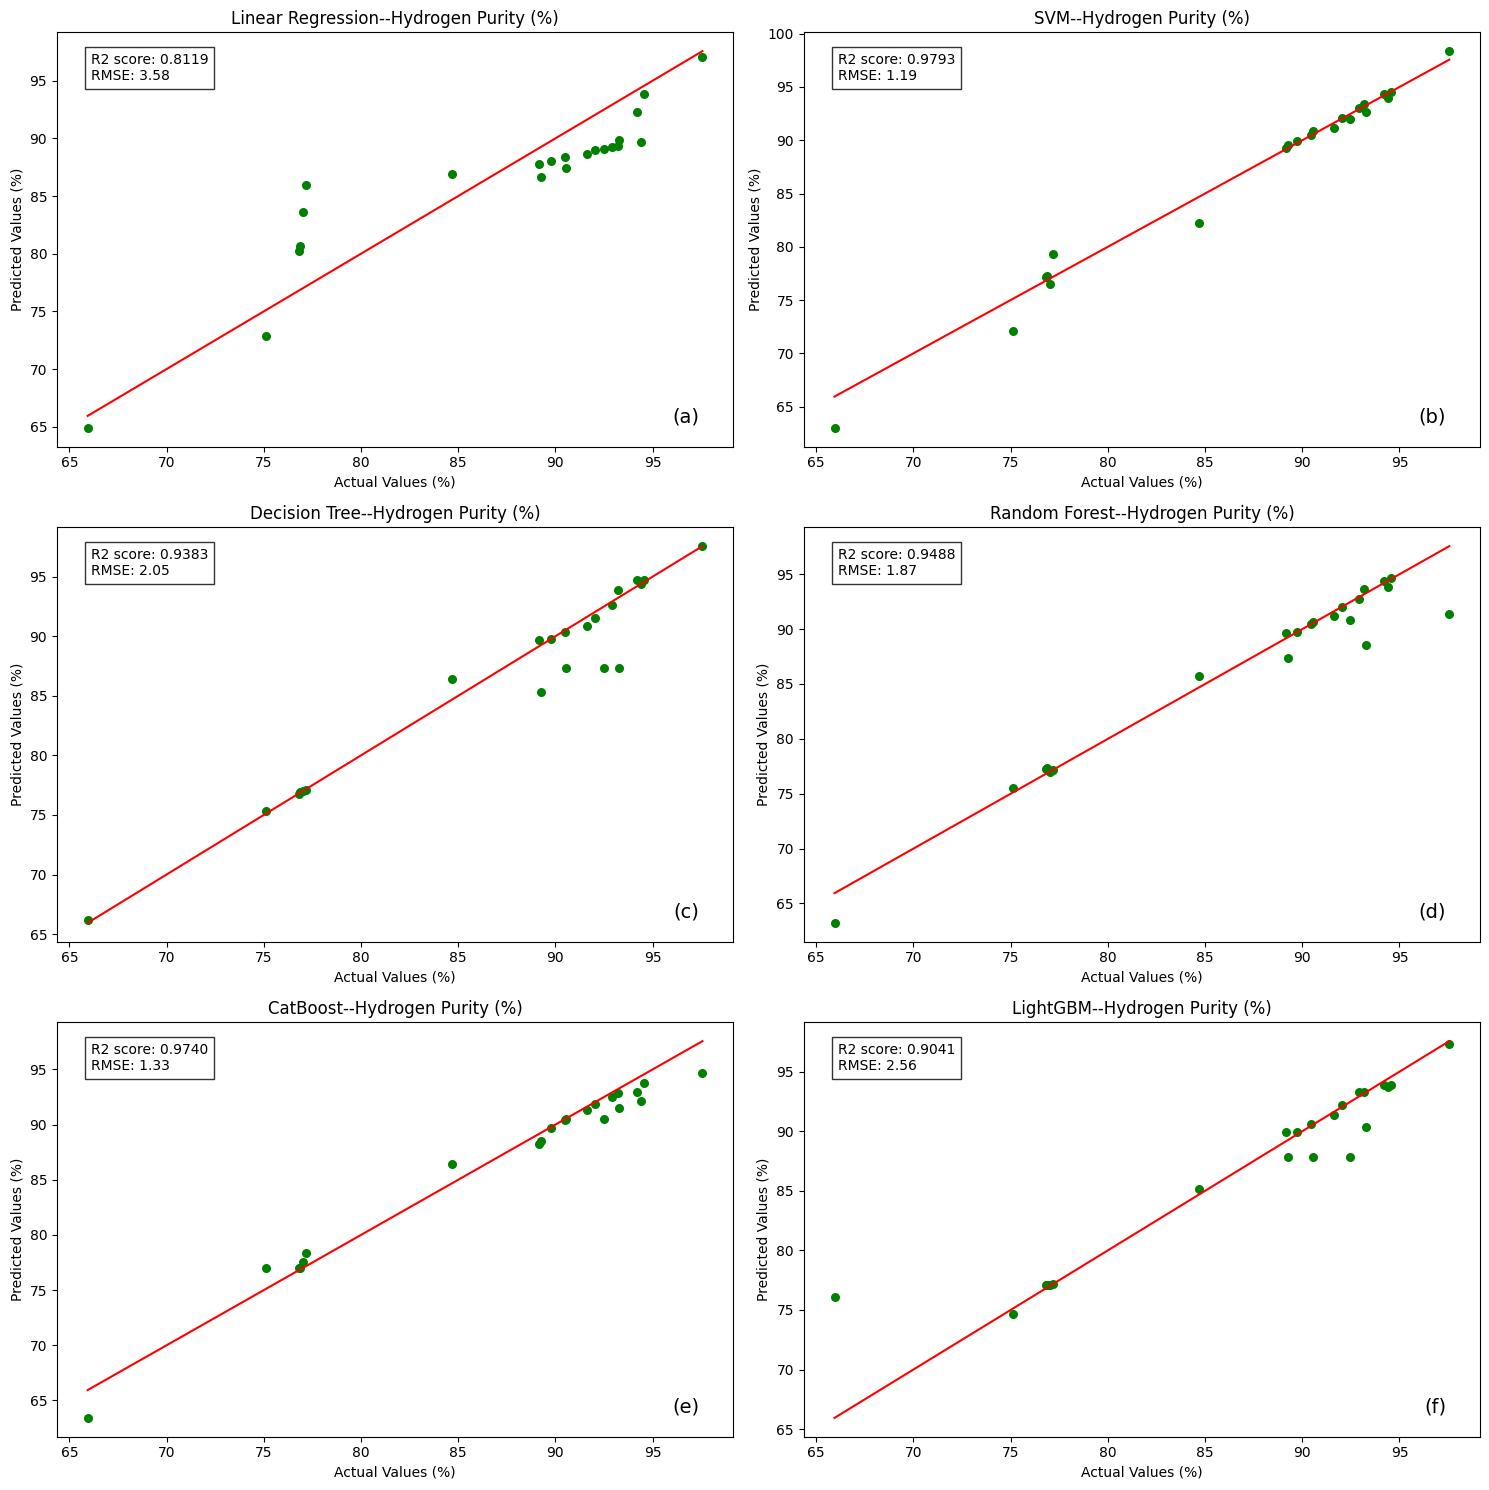

In [ ]:
plots_for_actual_vs_predicted(models=second_models, model_names=model_names, features=x, target=y2, output_to_predict='Hydrogen Purity')

# TRAIN AND TEST PLOTS FOR CARBONDIOXIDE CAPTURE

0:	learn: 8.2982593	total: 1.88ms	remaining: 222ms
1:	learn: 8.0711373	total: 8.05ms	remaining: 471ms
2:	learn: 7.8729854	total: 14.2ms	remaining: 550ms
3:	learn: 7.7138068	total: 14.4ms	remaining: 413ms
4:	learn: 7.5189825	total: 15.3ms	remaining: 349ms
5:	learn: 7.3590436	total: 15.9ms	remaining: 299ms
6:	learn: 7.2118771	total: 16.1ms	remaining: 258ms
7:	learn: 7.0231780	total: 16.3ms	remaining: 227ms
8:	learn: 6.8602111	total: 16.7ms	remaining: 204ms
9:	learn: 6.7084016	total: 22.8ms	remaining: 249ms
10:	learn: 6.5672175	total: 39.3ms	remaining: 386ms
11:	learn: 6.4243939	total: 46.2ms	remaining: 412ms
12:	learn: 6.2724903	total: 46.9ms	remaining: 383ms
13:	learn: 6.1207513	total: 47.2ms	remaining: 354ms
14:	learn: 5.9973000	total: 47.4ms	remaining: 328ms
15:	learn: 5.8849343	total: 47.7ms	remaining: 307ms
16:	learn: 5.7649485	total: 47.9ms	remaining: 288ms
17:	learn: 5.6468392	total: 107ms	remaining: 601ms
18:	learn: 5.5193011	total: 162ms	remaining: 850ms
19:	learn: 5.4226501	tot

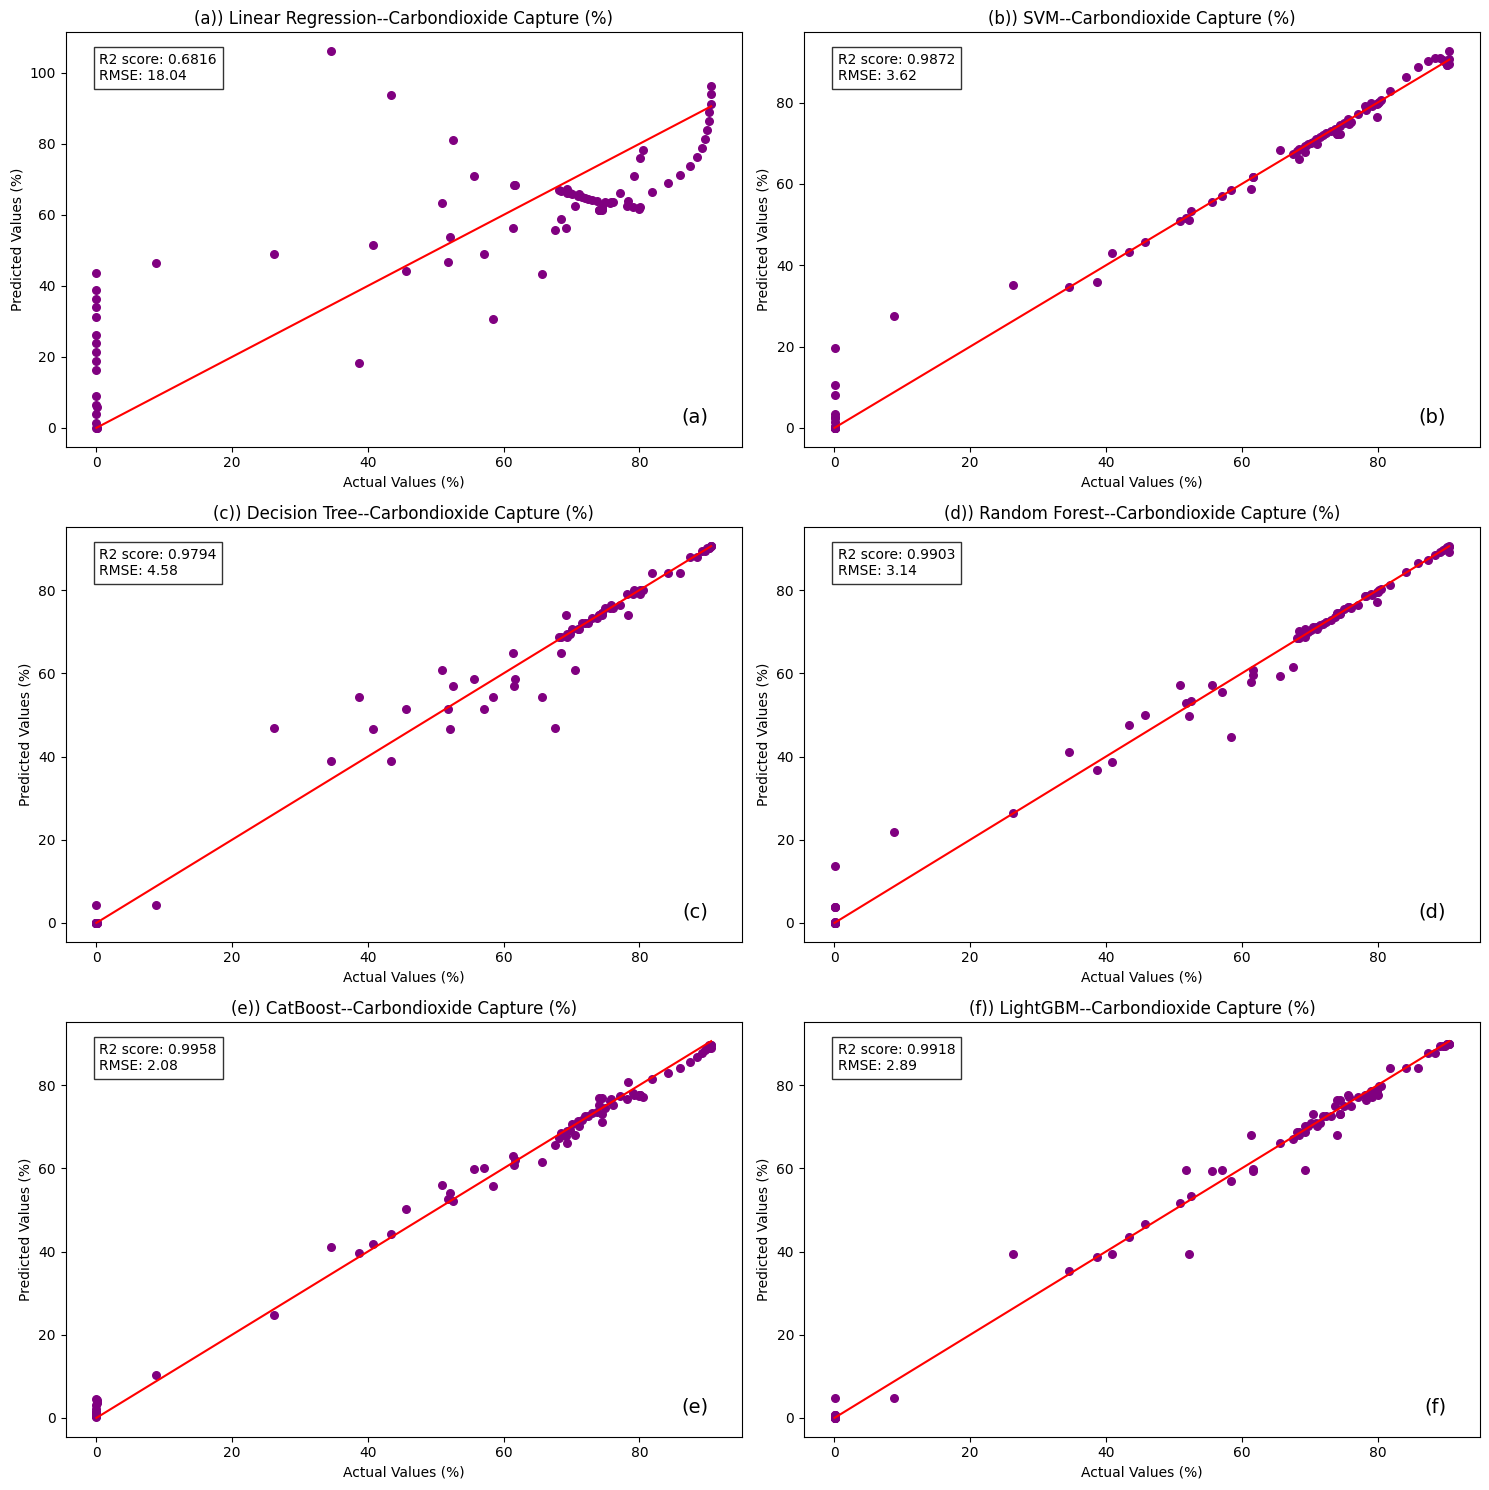

In [ ]:
plots_for_actual_vs_predicted_train(models=second_models, model_names=model_names, features=x, target=y2, output_to_predict='Carbondioxide Capture')

0:	learn: 8.2982593	total: 1.15ms	remaining: 135ms
1:	learn: 8.0711373	total: 5.06ms	remaining: 296ms
2:	learn: 7.8729854	total: 5.64ms	remaining: 218ms
3:	learn: 7.7138068	total: 5.75ms	remaining: 165ms
4:	learn: 7.5189825	total: 6.3ms	remaining: 144ms
5:	learn: 7.3590436	total: 6.64ms	remaining: 125ms
6:	learn: 7.2118771	total: 6.8ms	remaining: 109ms
7:	learn: 7.0231780	total: 6.95ms	remaining: 96.4ms
8:	learn: 6.8602111	total: 7.17ms	remaining: 87.6ms
9:	learn: 6.7084016	total: 8.07ms	remaining: 88ms
10:	learn: 6.5672175	total: 14.4ms	remaining: 141ms
11:	learn: 6.4243939	total: 16ms	remaining: 143ms
12:	learn: 6.2724903	total: 16.3ms	remaining: 133ms
13:	learn: 6.1207513	total: 16.5ms	remaining: 123ms
14:	learn: 5.9973000	total: 16.6ms	remaining: 115ms
15:	learn: 5.8849343	total: 16.8ms	remaining: 108ms
16:	learn: 5.7649485	total: 17ms	remaining: 102ms
17:	learn: 5.6468392	total: 44.1ms	remaining: 247ms
18:	learn: 5.5193011	total: 70.6ms	remaining: 372ms
19:	learn: 5.4226501	total:

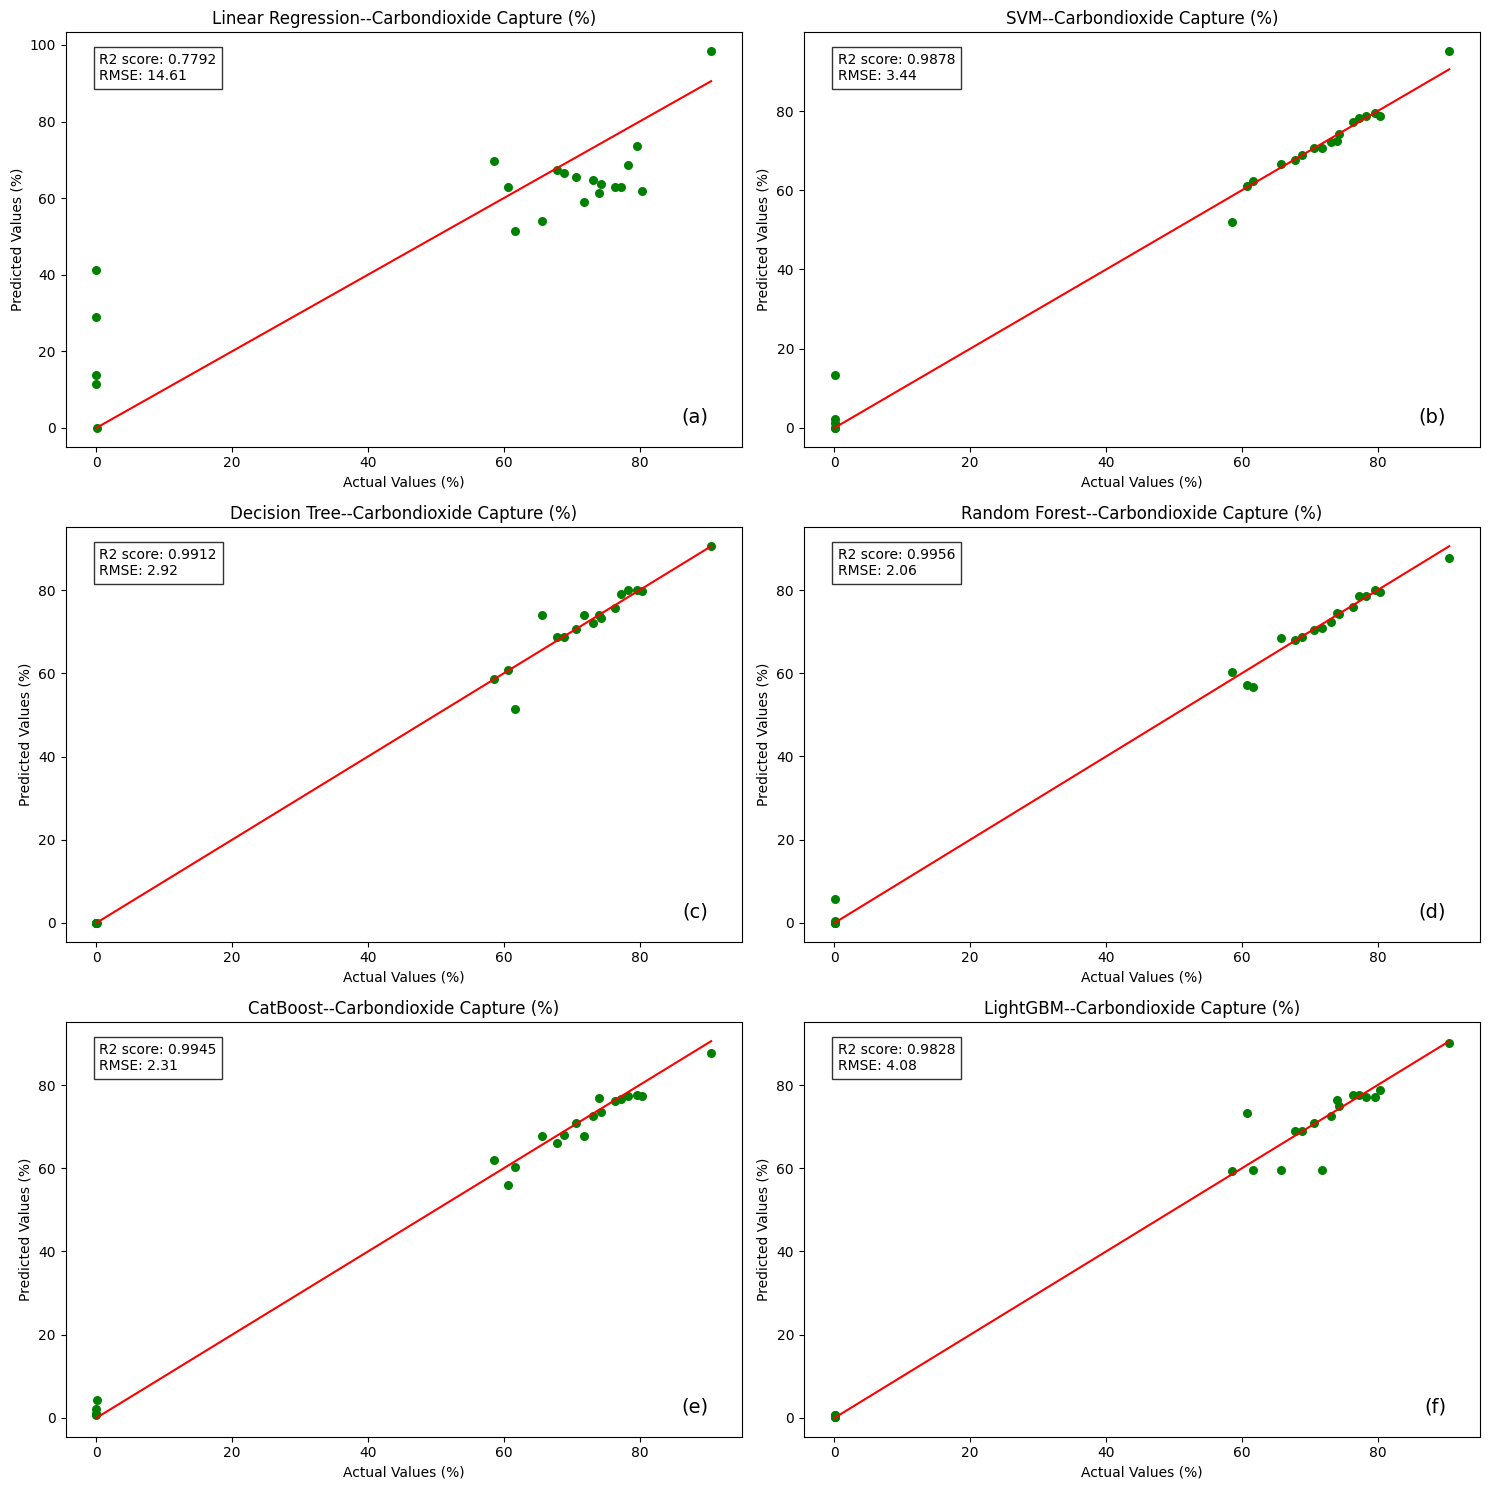

In [ ]:
plots_for_actual_vs_predicted(models=second_models, model_names=model_names, features=x, target=y2, output_to_predict='Carbondioxide Capture')

In [ ]:
# Function with train data only
def compute_feature_importances(models, feature_names, target_names):

  X_train, X_test, y_train, y_test = train_test_split(x, y1, test_size=0.2, random_state=42)

  importance_results = {}

  records = []
  for model_name, model in models.items():
    if model_name in ['Decision Tree', 'Random Forest', 'CatBoost', 'LightGBM']:

      model.fit(X_train, y_train)
      model_importances = {}

      for i, estimator in enumerate(model.estimators_):
          if hasattr(estimator, "feature_importances_"):
                raw_importance = estimator.feature_importances_
          elif hasattr(estimator, "get_feature_importance"):
                raw_importance = estimator.get_feature_importance()
          else:
                raw_importance = np.zeros(X_train.shape[1])
          normalized_importance = raw_importance / raw_importance.sum()

            # Store both raw and normalized as separate columns
          record = {
                'Model': model_name,
                'Target': target_names[i]
            }
          record.update(dict(zip(feature_names, normalized_importance)))
          records.append(record)

  importance_df = pd.DataFrame(records)
  return importance_df

In [ ]:
compute_feature_importances(models=models, feature_names=feature_columns, target_names=target1_names)

0:	learn: 13.7114144	total: 46.5ms	remaining: 5.58s
1:	learn: 13.3859840	total: 53.3ms	remaining: 3.17s
2:	learn: 13.0722507	total: 54.4ms	remaining: 2.14s
3:	learn: 12.7393663	total: 55ms	remaining: 1.61s
4:	learn: 12.4481618	total: 55.2ms	remaining: 1.28s
5:	learn: 12.1313663	total: 59.9ms	remaining: 1.15s
6:	learn: 11.8108733	total: 64.4ms	remaining: 1.05s
7:	learn: 11.5047853	total: 69ms	remaining: 975ms
8:	learn: 11.2403878	total: 88.2ms	remaining: 1.1s
9:	learn: 11.0589463	total: 88.3ms	remaining: 980ms
10:	learn: 10.7964662	total: 90.4ms	remaining: 904ms
11:	learn: 10.5292894	total: 107ms	remaining: 969ms
12:	learn: 10.2666959	total: 122ms	remaining: 1.01s
13:	learn: 10.0249566	total: 122ms	remaining: 932ms
14:	learn: 9.8244231	total: 122ms	remaining: 864ms
15:	learn: 9.5677777	total: 126ms	remaining: 827ms
16:	learn: 9.3307759	total: 127ms	remaining: 774ms
17:	learn: 9.1078831	total: 127ms	remaining: 726ms
18:	learn: 8.9255382	total: 127ms	remaining: 681ms
19:	learn: 8.6972595	

,Model,Target,Reformer Temperature,Reformer Pressure,S/C,CaO/C
0,Decision Tree,Methane Conversion,0.279712,0.649344,0.069727,0.001217
1,Decision Tree,Hydrogen Yield,0.248593,0.661914,0.081407,0.008087
2,Random Forest,Methane Conversion,0.253763,0.690827,0.054698,0.000711
3,Random Forest,Hydrogen Yield,0.223646,0.698250,0.066630,0.011474
4,CatBoost,Methane Conversion,0.336383,0.558028,0.099811,0.005778
5,CatBoost,Hydrogen Yield,0.268977,0.539784,0.165752,0.025488
6,LightGBM,Methane Conversion,0.403846,0.314103,0.237179,0.044872
7,LightGBM,Hydrogen Yield,0.391026,0.294872,0.243590,0.070513


In [ ]:
def plot_feature_importances_dual_targets(models, feature_names, target_names):

    importance_df = compute_feature_importances(models, feature_names, target_names)
    models = importance_df['Model'].unique()
    assert len(models) == 4, "This function assumes exactly 4 models."

    colors = {target_names[0]: 'green', target_names[1]: 'purple'}
    subplot_labels = ['(a)', '(b)', '(c)', '(d)']

    for target in target_names:
        fig, axes = plt.subplots(2, 2, figsize=(18, 10))
        axes = axes.flatten()
        fig.suptitle(f'Feature Importances for Target: {target}', fontsize=16, y=0.95)

        for idx, model in enumerate(models):
            ax = axes[idx]
            subset = importance_df[(importance_df['Model'] == model) & (importance_df['Target'] == target)]

            # Extract importance values for features, convert to array
            importances = subset[feature_names].values.flatten()
            # Sort features by importance descending for nicer visuals
            sorted_idx = np.argsort(importances)[::-1]
            sorted_features = [feature_names[i] for i in sorted_idx]
            sorted_importances = importances[sorted_idx]

            bars = ax.barh(sorted_features, sorted_importances, color=colors[target])
            ax.invert_yaxis()
            ax.set_ylabel('Features', fontsize=12)
            ax.set_xlabel('Normalized Importance', fontsize=12)
            ax.set_title(model, fontsize=14)
            ax.grid(axis='x', linestyle='--', alpha=0.7)

            # Add labels to bars (3 decimal places)
            for bar, importance in zip(bars, sorted_importances):
                width = bar.get_width()
                if width >= 0.03:
                    # Label inside the bar
                    ax.text(
                        width * 0.98,
                        bar.get_y() + bar.get_height() / 2,
                        f'{importance:.3f}',
                        ha='right',
                        va='center',
                        fontsize=9,
                        color='black'
                    )
                else:
                    # Label outside the bar
                    ax.text(
                        width + 0.01,
                        bar.get_y() + bar.get_height() / 2,
                        f'{importance:.3f}',
                        ha='left',
                        va='center',
                        fontsize=9,
                        color='black'
                    )
            ax.text(0.95, 0.05, subplot_labels[idx],
                    transform=ax.transAxes,
                    verticalalignment='bottom',
                    horizontalalignment='right',
                    fontsize=14)


        plt.tight_layout(rect=[0, 0, 1, 0.93])
        plt.show()

0:	learn: 13.7114144	total: 1.16ms	remaining: 140ms
1:	learn: 13.3859840	total: 16.1ms	remaining: 959ms
2:	learn: 13.0722507	total: 18.6ms	remaining: 730ms
3:	learn: 12.7393663	total: 20.3ms	remaining: 593ms
4:	learn: 12.4481618	total: 20.6ms	remaining: 478ms
5:	learn: 12.1313663	total: 30.9ms	remaining: 593ms
6:	learn: 11.8108733	total: 39.3ms	remaining: 640ms
7:	learn: 11.5047853	total: 44.7ms	remaining: 631ms
8:	learn: 11.2403878	total: 83.9ms	remaining: 1.04s
9:	learn: 11.0589463	total: 84.1ms	remaining: 933ms
10:	learn: 10.7964662	total: 86.5ms	remaining: 865ms
11:	learn: 10.5292894	total: 106ms	remaining: 961ms
12:	learn: 10.2666959	total: 124ms	remaining: 1.03s
13:	learn: 10.0249566	total: 125ms	remaining: 954ms
14:	learn: 9.8244231	total: 125ms	remaining: 885ms
15:	learn: 9.5677777	total: 130ms	remaining: 852ms
16:	learn: 9.3307759	total: 131ms	remaining: 799ms
17:	learn: 9.1078831	total: 131ms	remaining: 749ms
18:	learn: 8.9255382	total: 131ms	remaining: 704ms
19:	learn: 8.697

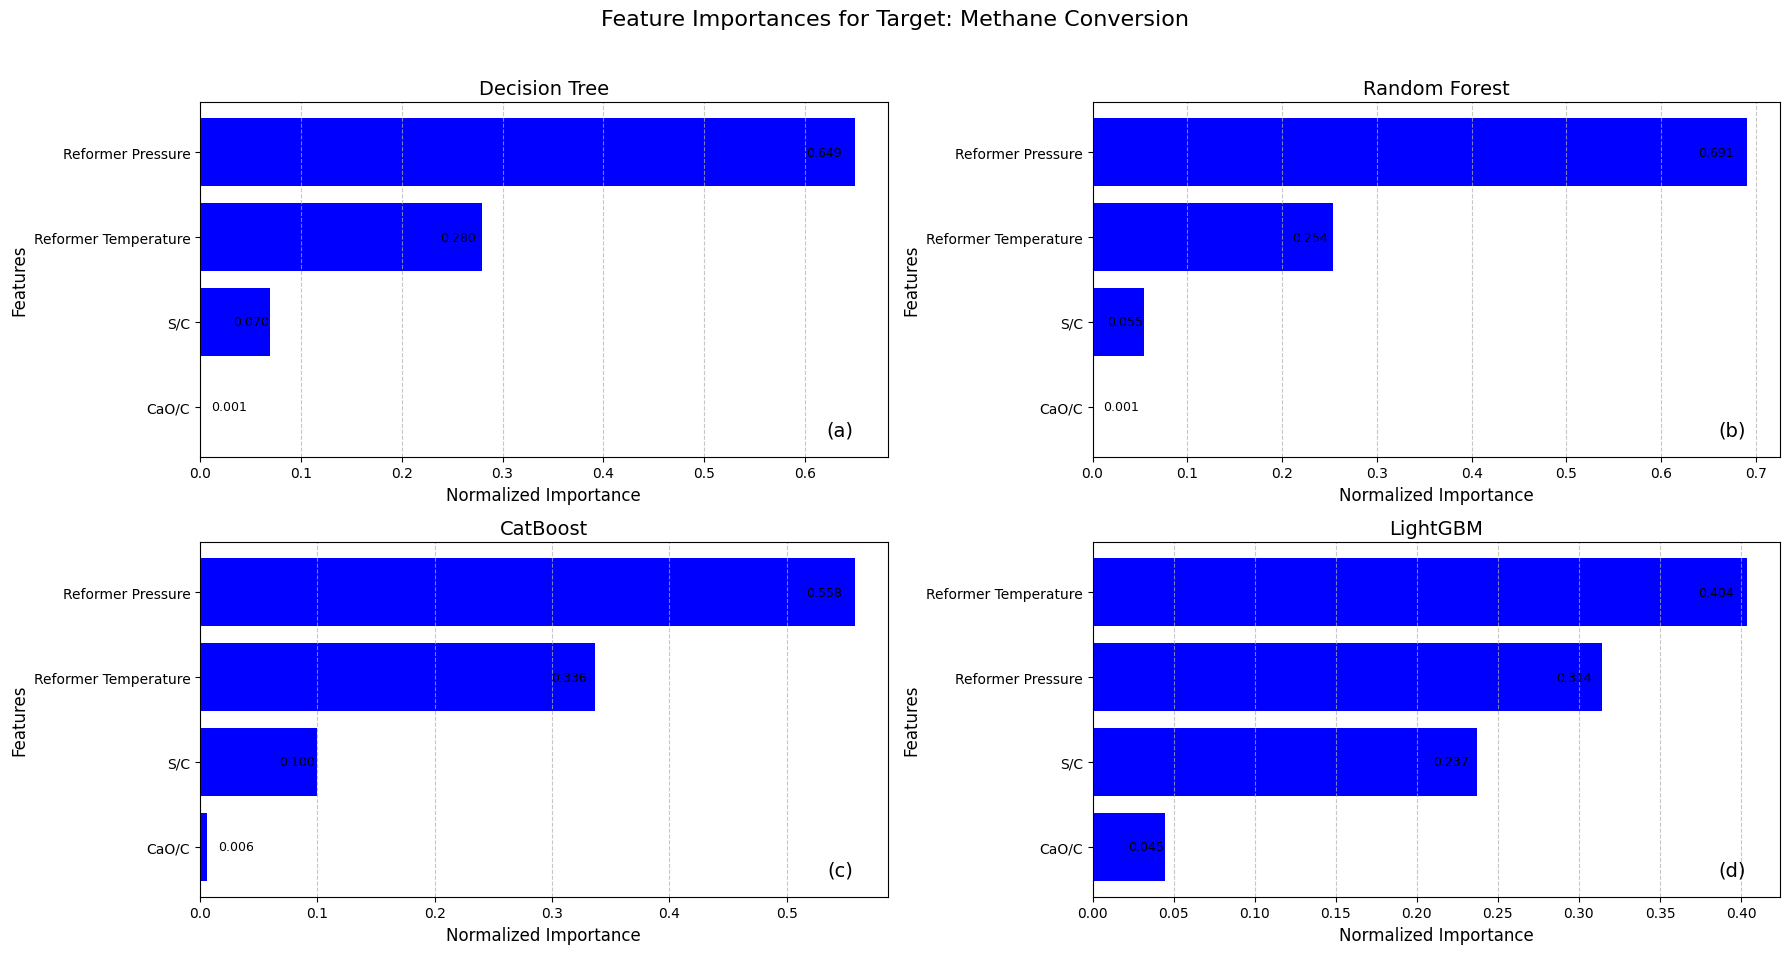

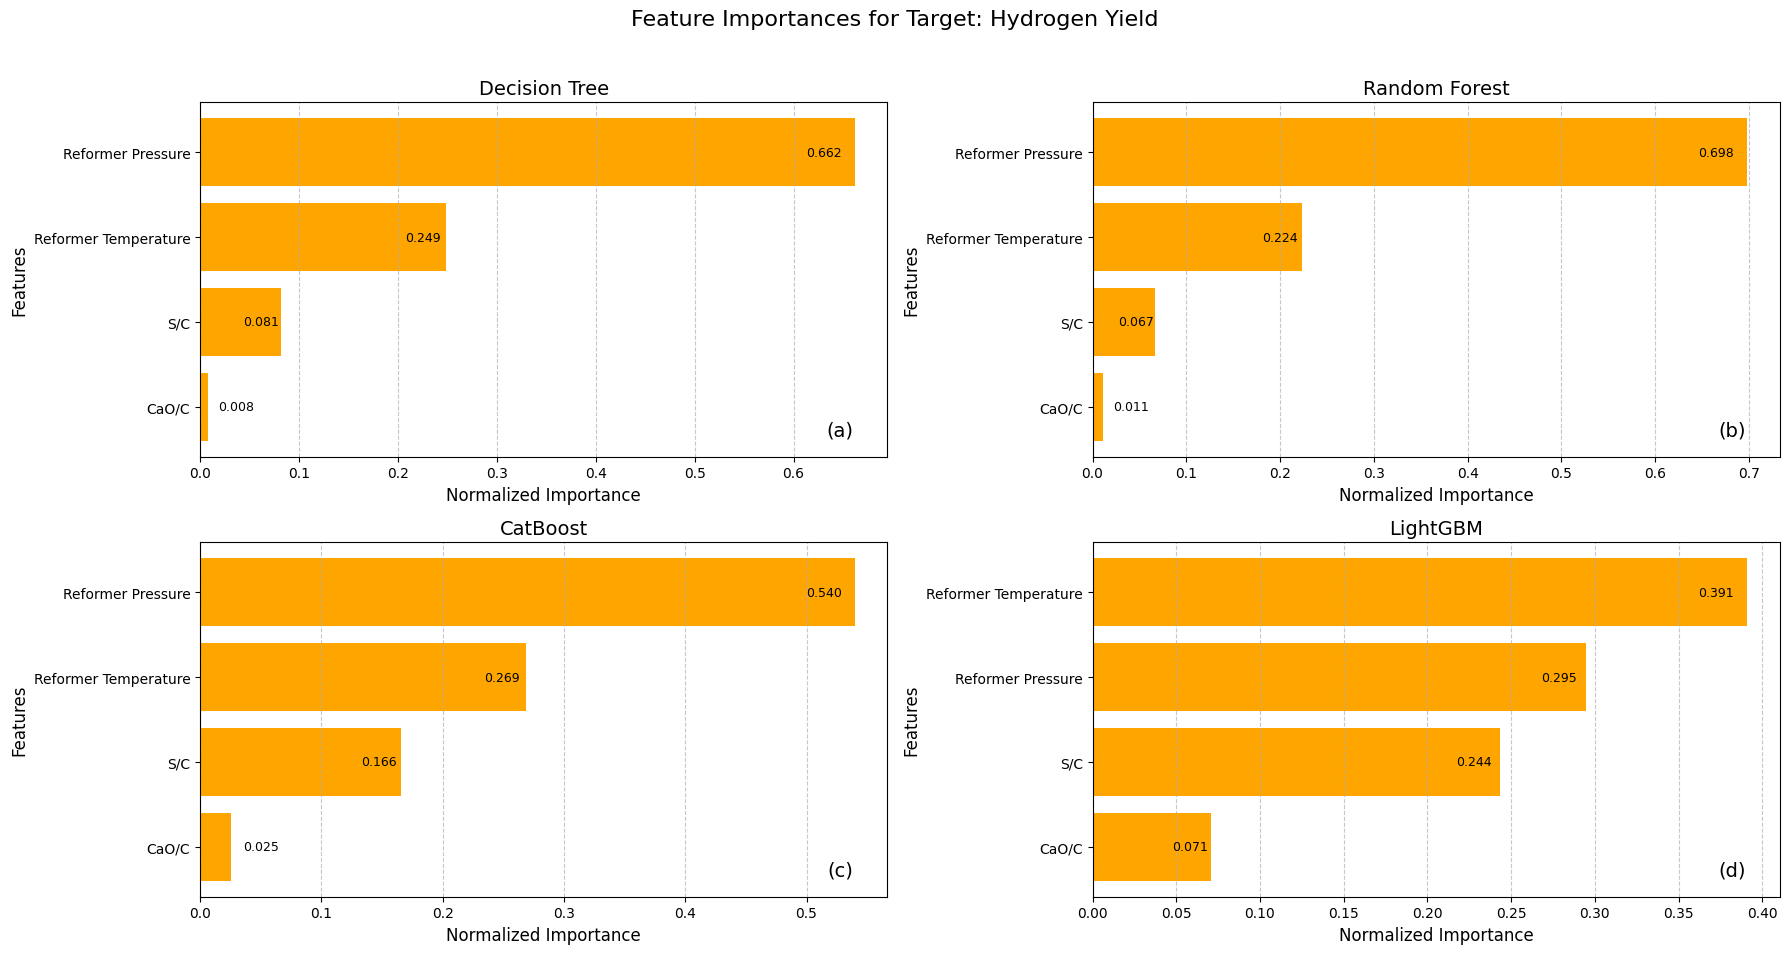

In [ ]:
plot_feature_importances_dual_targets(models=models, feature_names=feature_columns, target_names=target1_names)

0:	learn: 13.6785330	total: 664us	remaining: 78.4ms
1:	learn: 13.3496114	total: 12.7ms	remaining: 743ms
2:	learn: 13.0421993	total: 13.3ms	remaining: 513ms
3:	learn: 12.6812986	total: 20.2ms	remaining: 582ms
4:	learn: 12.3828489	total: 24.4ms	remaining: 556ms
5:	learn: 12.0821137	total: 24.7ms	remaining: 464ms
6:	learn: 11.7446607	total: 25.9ms	remaining: 414ms
7:	learn: 11.4027597	total: 31ms	remaining: 430ms
8:	learn: 11.1394458	total: 89.4ms	remaining: 1.09s
9:	learn: 10.8261513	total: 90ms	remaining: 981ms
10:	learn: 10.5689118	total: 91.1ms	remaining: 895ms
11:	learn: 10.2965651	total: 101ms	remaining: 904ms
12:	learn: 10.0269116	total: 102ms	remaining: 828ms
13:	learn: 9.7994135	total: 102ms	remaining: 764ms
14:	learn: 9.5461978	total: 135ms	remaining: 933ms
15:	learn: 9.3154692	total: 168ms	remaining: 1.08s
16:	learn: 9.0987755	total: 169ms	remaining: 1.02s
17:	learn: 8.9017382	total: 170ms	remaining: 952ms
18:	learn: 8.7036747	total: 205ms	remaining: 1.08s
19:	learn: 8.4789447	

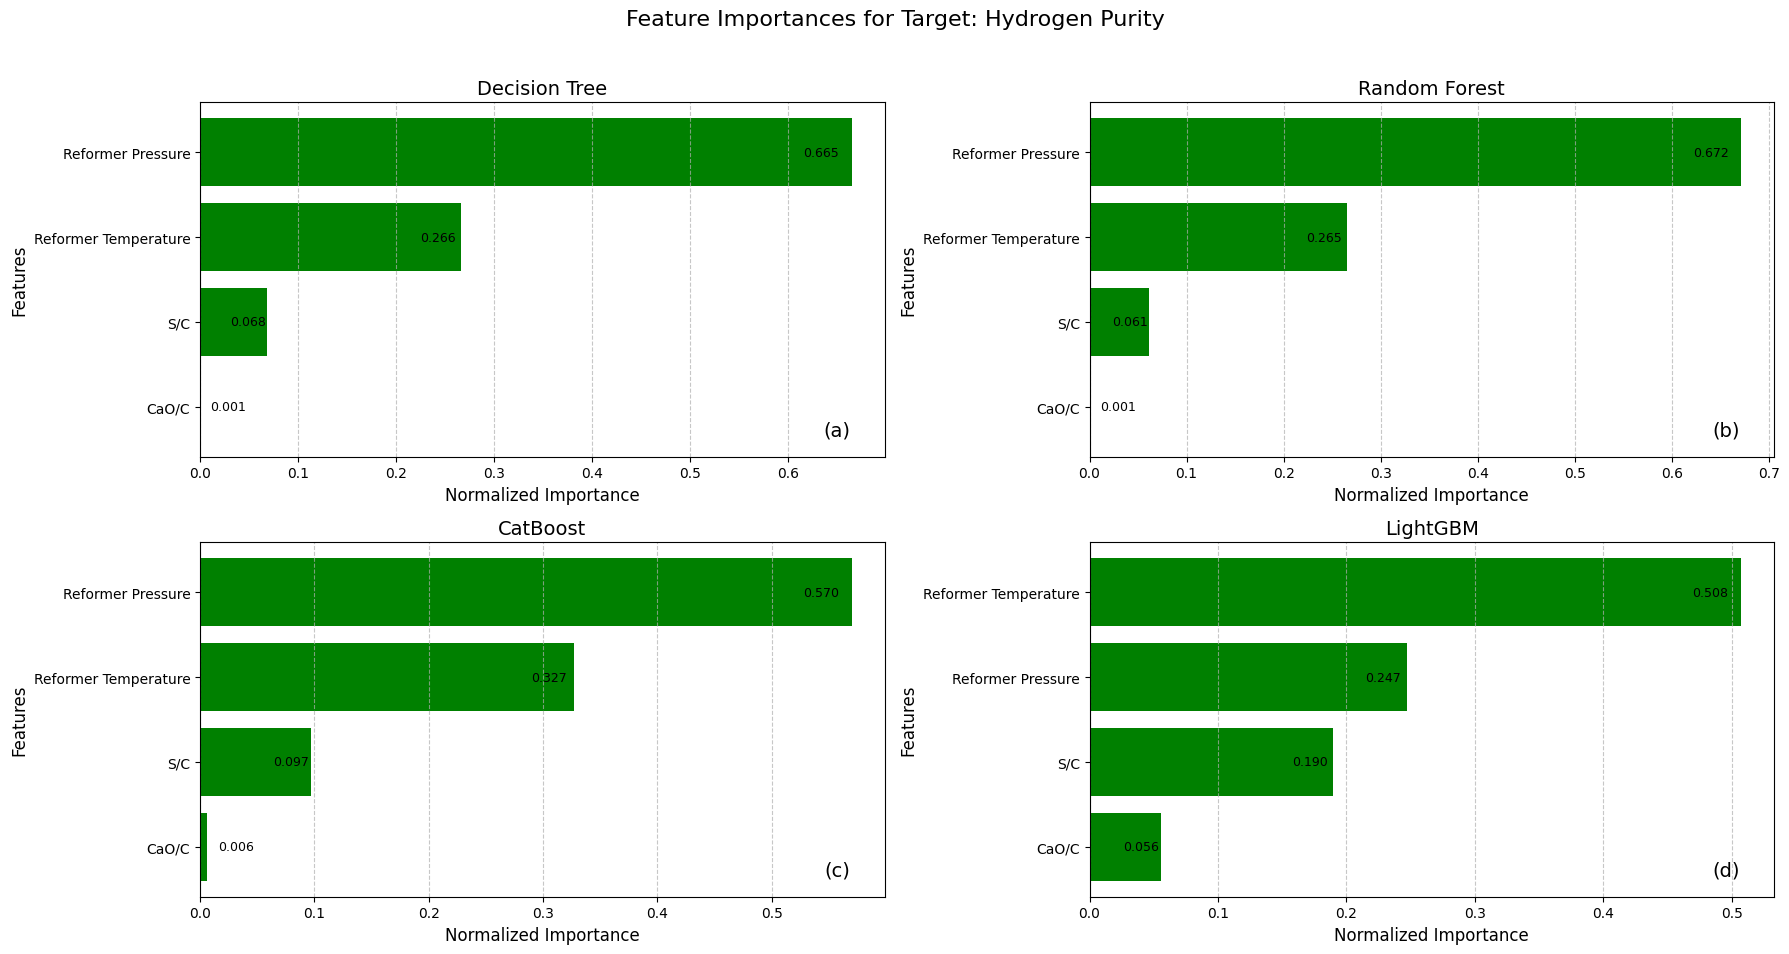

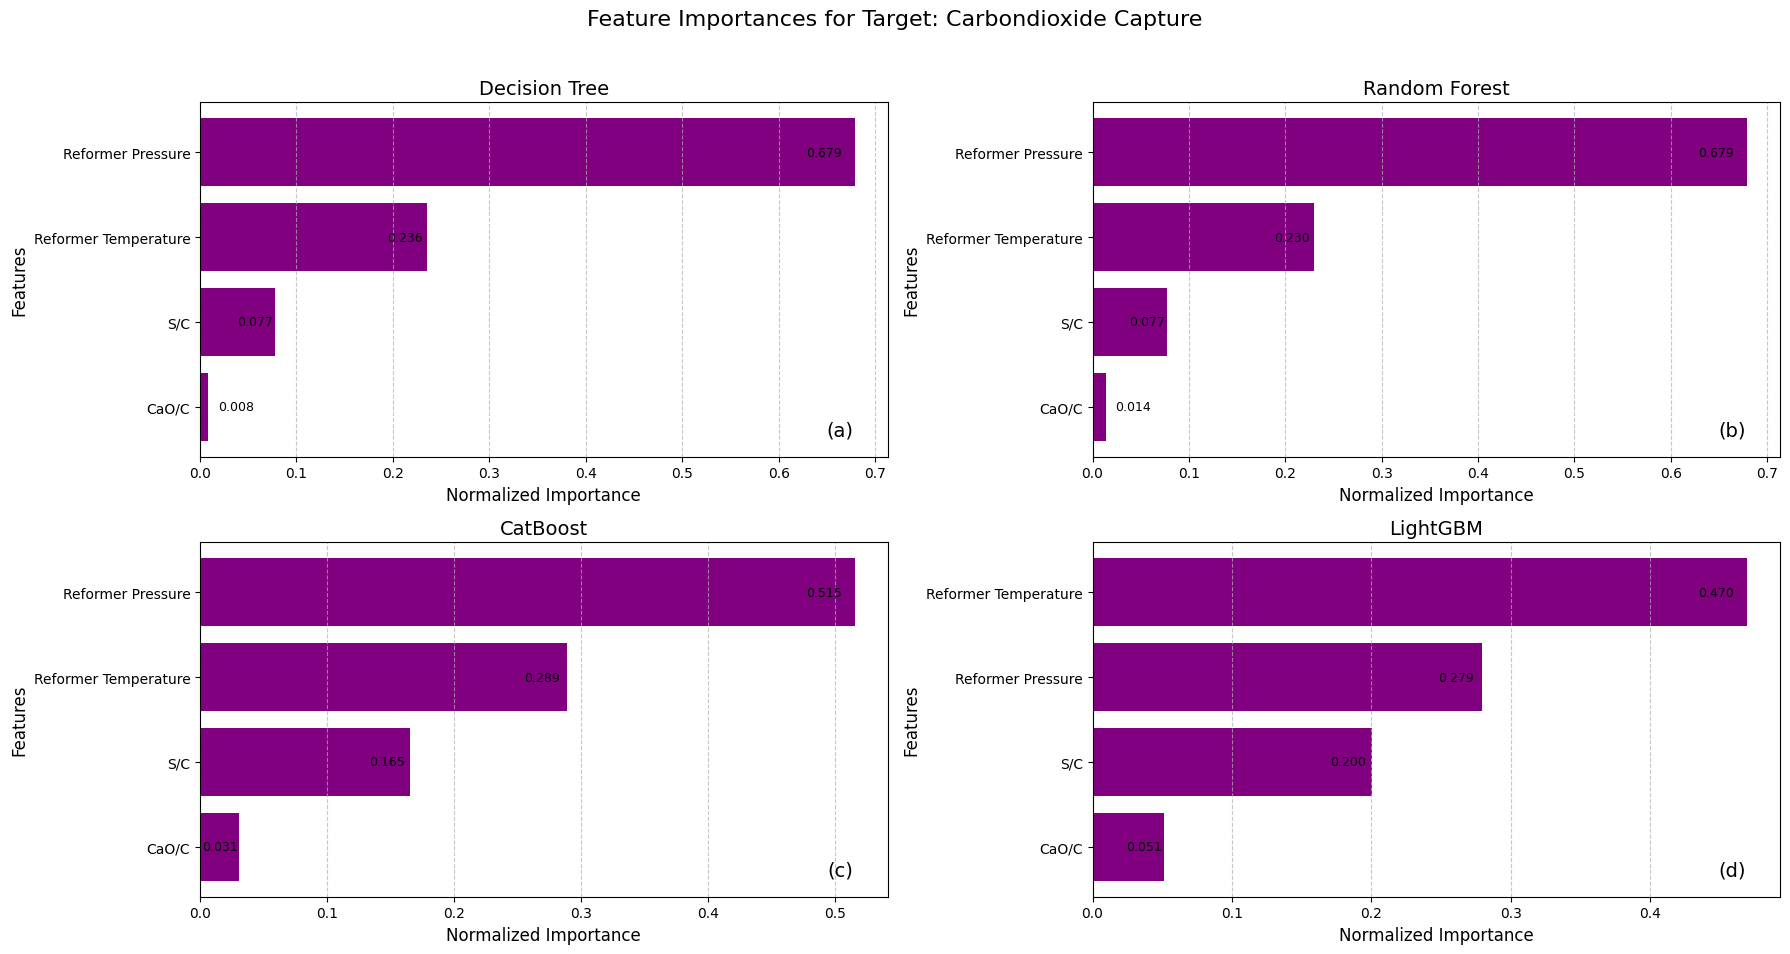

In [ ]:
plot_feature_importances_dual_targets(models=second_models, feature_names=feature_columns, target_names=target2_names)

# **BAYESIAN OPTIMIZATION HYPERPARAMETER TUNING FOR METHANE CONVERSION AND HYDROGEN YIELD**

### SVM HYPERPARAMETER TUNING

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y1, test_size= 0.2, random_state=42)

In [ ]:
def objective(trial):
    params = {
        'kernel': trial.suggest_categorical('kernel', ['rbf']),
        'C': trial.suggest_int('C', 1800, 1900),
        'gamma': trial.suggest_loguniform('gamma', 1.4, 1.6),
    }


    model = MultiOutputRegressor(SVR(**params, verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(SVR(**best_params, verbose=0))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

NameError: name 'optuna' is not defined

## DECISION TREE HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
         'max_depth': trial.suggest_int('max_depth', 40, 70),
       'min_samples_split': trial.suggest_int('min_samples_split', 2, 3),
       'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 2),
        'random_state': 42
    }

    model = MultiOutputRegressor(DecisionTreeRegressor(**params))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(DecisionTreeRegressor(**best_params, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-22 13:31:30,713] A new study created in memory with name: no-name-7e27c1b1-8b5b-4e42-bbfd-7e9cb3434bba
[I 2025-05-22 13:31:30,749] Trial 0 finished with value: 1.7791987790729138 and parameters: {'max_depth': 58, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 0 with value: 1.7791987790729138.
[I 2025-05-22 13:31:30,770] Trial 1 finished with value: 1.9206022670458915 and parameters: {'max_depth': 43, 'min_samples_split': 3, 'min_samples_leaf': 2}. Best is trial 0 with value: 1.7791987790729138.
[I 2025-05-22 13:31:30,787] Trial 2 finished with value: 1.7791987790729138 and parameters: {'max_depth': 48, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 0 with value: 1.7791987790729138.
[I 2025-05-22 13:31:30,804] Trial 3 finished with value: 1.7791987790729138 and parameters: {'max_depth': 56, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 0 with value: 1.7791987790729138.
[I 2025-05-22 13:31:30,821] Trial 4 finished with value: 1.690

Best RMSE: 1.6907436838697507
Best hyperparameters: {'max_depth': 40, 'min_samples_split': 2, 'min_samples_leaf': 1}
Final RMSE: 1.6907436838697507


In [ ]:
def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 40, 70),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 3),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 2),
        'random_state': 42
    }

    model = MultiOutputRegressor(DecisionTreeRegressor(**params))

    # Use 5-Fold Cross-Validation on the training set
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    # Use negative MSE because sklearn's cross_val_score uses "greater_is_better"
    scores = cross_val_score(model, X_train, y_train, cv=kf,
                             scoring='neg_mean_squared_error')

    rmse = np.mean(np.sqrt(-scores))  # Convert to positive RMSE
    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(DecisionTreeRegressor(**best_params, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')



[I 2025-07-11 02:22:02,263] A new study created in memory with name: no-name-1b13f341-f2ad-48c6-8ace-28a6f1a69afc
[I 2025-07-11 02:22:02,323] Trial 0 finished with value: 2.6524475529830864 and parameters: {'max_depth': 41, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 0 with value: 2.6524475529830864.
[I 2025-07-11 02:22:02,376] Trial 1 finished with value: 2.3942623933696736 and parameters: {'max_depth': 61, 'min_samples_split': 2, 'min_samples_leaf': 2}. Best is trial 1 with value: 2.3942623933696736.
[I 2025-07-11 02:22:02,429] Trial 2 finished with value: 2.6524475529830864 and parameters: {'max_depth': 42, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 1 with value: 2.3942623933696736.
[I 2025-07-11 02:22:02,482] Trial 3 finished with value: 2.3942623933696736 and parameters: {'max_depth': 60, 'min_samples_split': 2, 'min_samples_leaf': 2}. Best is trial 1 with value: 2.3942623933696736.
[I 2025-07-11 02:22:02,544] Trial 4 finished with value: 2.394

Best RMSE: 2.3942623933696736
Best hyperparameters: {'max_depth': 61, 'min_samples_split': 2, 'min_samples_leaf': 2}
Final RMSE: 1.9206022670458915


# CATBOOST HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 120, 130),
        'depth': trial.suggest_int('depth', 12, 15),
        'l2_leaf_reg': trial.suggest_int('l2_leaf_reg', 1, 2),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.02, 0.04),
        'random_state': 42
    }

    model = MultiOutputRegressor(CatBoostRegressor(**params, eval_metric='RMSE', verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(CatBoostRegressor(**best_params, eval_metric='RMSE', verbose=0, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-28 16:49:27,947] A new study created in memory with name: no-name-40571a8e-6d7f-4b3f-8431-35acec8c7e20
<ipython-input-16-32f7fb08e58e>:6: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.02, 0.04),
[I 2025-05-28 16:49:28,746] Trial 0 finished with value: 2.1532801762563336 and parameters: {'iterations': 130, 'depth': 12, 'l2_leaf_reg': 1, 'learning_rate': 0.030671630733306057}. Best is trial 0 with value: 2.1532801762563336.
<ipython-input-16-32f7fb08e58e>:6: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.02, 0.04),
[I 2025-05-28 16:49:31,879]

Best RMSE: 1.8943775888291234
Best hyperparameters: {'iterations': 130, 'depth': 15, 'l2_leaf_reg': 2, 'learning_rate': 0.039169629418211845}
Final RMSE: 1.8943775888291234


# LIGHTGBM HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 45, 52),
        'num_leaves': trial.suggest_int('num_leaves', 2, 4),
        'max_depth': trial.suggest_int('max_depth', 4, 12),
        'min_data_in_leaf': trial.suggest_int( 'min_data_in_leaf', 1, 2),
        'random_state': 42
    }

    model = MultiOutputRegressor(LGBMRegressor(**params, eval_metric='RMSE', verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(LGBMRegressor(**best_params, eval_metric='RMSE', verbose=0, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-22 15:04:20,376] A new study created in memory with name: no-name-59e09fcd-5638-4a82-a1cd-48ca128ca28c
[I 2025-05-22 15:04:20,406] Trial 0 finished with value: 2.2469634949841675 and parameters: {'n_estimators': 51, 'num_leaves': 3, 'max_depth': 11, 'min_data_in_leaf': 1}. Best is trial 0 with value: 2.2469634949841675.
[I 2025-05-22 15:04:20,431] Trial 1 finished with value: 3.8302163551010424 and parameters: {'n_estimators': 47, 'num_leaves': 2, 'max_depth': 11, 'min_data_in_leaf': 2}. Best is trial 0 with value: 2.2469634949841675.
[I 2025-05-22 15:04:20,454] Trial 2 finished with value: 3.805285302416137 and parameters: {'n_estimators': 52, 'num_leaves': 2, 'max_depth': 12, 'min_data_in_leaf': 1}. Best is trial 0 with value: 2.2469634949841675.
[I 2025-05-22 15:04:20,479] Trial 3 finished with value: 3.845896370003685 and parameters: {'n_estimators': 46, 'num_leaves': 2, 'max_depth': 5, 'min_data_in_leaf': 1}. Best is trial 0 with value: 2.2469634949841675.
[I 2025-05-22

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value:

[I 2025-05-22 15:04:20,608] Trial 8 finished with value: 3.7958915740207817 and parameters: {'n_estimators': 50, 'num_leaves': 2, 'max_depth': 9, 'min_data_in_leaf': 1}. Best is trial 0 with value: 2.2469634949841675.
[I 2025-05-22 15:04:20,633] Trial 9 finished with value: 2.760223097911096 and parameters: {'n_estimators': 50, 'num_leaves': 4, 'max_depth': 10, 'min_data_in_leaf': 2}. Best is trial 0 with value: 2.2469634949841675.
[I 2025-05-22 15:04:20,684] Trial 10 finished with value: 2.2391138670985598 and parameters: {'n_estimators': 52, 'num_leaves': 3, 'max_depth': 4, 'min_data_in_leaf': 1}. Best is trial 10 with value: 2.2391138670985598.
[I 2025-05-22 15:04:20,732] Trial 11 finished with value: 2.2391138670985598 and parameters: {'n_estimators': 52, 'num_leaves': 3, 'max_depth': 4, 'min_data_in_leaf': 1}. Best is trial 10 with value: 2.2391138670985598.
[I 2025-05-22 15:04:20,777] Trial 12 finished with value: 2.2391138670985598 and parameters: {'n_estimators': 52, 'num_leave

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value:

[I 2025-05-22 15:04:20,829] Trial 13 finished with value: 2.273173491986878 and parameters: {'n_estimators': 50, 'num_leaves': 3, 'max_depth': 5, 'min_data_in_leaf': 1}. Best is trial 10 with value: 2.2391138670985598.
[I 2025-05-22 15:04:20,880] Trial 14 finished with value: 2.230897064162178 and parameters: {'n_estimators': 52, 'num_leaves': 4, 'max_depth': 4, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:20,932] Trial 15 finished with value: 2.2478914277439173 and parameters: {'n_estimators': 49, 'num_leaves': 4, 'max_depth': 6, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:20,981] Trial 16 finished with value: 2.2334337740714907 and parameters: {'n_estimators': 51, 'num_leaves': 4, 'max_depth': 6, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value:

... (34 outputs left out)

[I 2025-05-22 15:04:24,740] Trial 92 finished with value: 2.230897064162178 and parameters: {'n_estimators': 52, 'num_leaves': 4, 'max_depth': 9, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:24,793] Trial 93 finished with value: 2.230897064162178 and parameters: {'n_estimators': 52, 'num_leaves': 4, 'max_depth': 9, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:24,842] Trial 94 finished with value: 2.230897064162178 and parameters: {'n_estimators': 52, 'num_leaves': 4, 'max_depth': 10, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:24,892] Trial 95 finished with value: 2.2334337740714907 and parameters: {'n_estimators': 51, 'num_leaves': 4, 'max_depth': 7, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value:

[I 2025-05-22 15:04:24,943] Trial 96 finished with value: 2.239299317476375 and parameters: {'n_estimators': 47, 'num_leaves': 4, 'max_depth': 8, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:24,997] Trial 97 finished with value: 2.230897064162178 and parameters: {'n_estimators': 52, 'num_leaves': 4, 'max_depth': 9, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:25,055] Trial 98 finished with value: 2.77130491557216 and parameters: {'n_estimators': 51, 'num_leaves': 4, 'max_depth': 8, 'min_data_in_leaf': 2}. Best is trial 14 with value: 2.230897064162178.
[I 2025-05-22 15:04:25,103] Trial 99 finished with value: 2.2391138670985598 and parameters: {'n_estimators': 52, 'num_leaves': 3, 'max_depth': 4, 'min_data_in_leaf': 1}. Best is trial 14 with value: 2.230897064162178.


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value:

# RANDOM FOREST HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 15, 26),
        'max_depth': trial.suggest_int('max_depth', 10, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 4),
        'min_samples_leaf': trial.suggest_int( 'min_samples_leaf', 1, 3),
        'random_state': 42
    }

    model = MultiOutputRegressor(RandomForestRegressor(**params, verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(RandomForestRegressor(**best_params, verbose=0, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-22 14:58:23,884] A new study created in memory with name: no-name-583b78b9-2047-4349-9e8c-391f54312477
[I 2025-05-22 14:58:24,160] Trial 0 finished with value: 1.5432405621278344 and parameters: {'n_estimators': 15, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 2}. Best is trial 0 with value: 1.5432405621278344.
[I 2025-05-22 14:58:24,635] Trial 1 finished with value: 1.292787465306576 and parameters: {'n_estimators': 23, 'max_depth': 20, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 1 with value: 1.292787465306576.
[I 2025-05-22 14:58:24,863] Trial 2 finished with value: 1.5432405621278344 and parameters: {'n_estimators': 15, 'max_depth': 13, 'min_samples_split': 3, 'min_samples_leaf': 2}. Best is trial 1 with value: 1.292787465306576.
[I 2025-05-22 14:58:25,002] Trial 3 finished with value: 1.5432405621278344 and parameters: {'n_estimators': 15, 'max_depth': 19, 'min_samples_split': 3, 'min_samples_leaf': 2}. Best is trial 1 with value: 1.292

Best RMSE: 1.2248242060778223
Best hyperparameters: {'n_estimators': 23, 'max_depth': 17, 'min_samples_split': 3, 'min_samples_leaf': 2}
Final RMSE: 1.2248242060778223


#**BAYESIAN OPTIMIZATION HYPERPARAMETER TUNING FOR HYDROGEN PURITY AND CARBONDIOXIDE CAPTURE**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y2, test_size= 0.2, random_state=42)

# SVM HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
        'kernel': trial.suggest_categorical('kernel', ['rbf']),
        'C': trial.suggest_int('C',  33000, 35000),
        'gamma': trial.suggest_loguniform('gamma', 6.0, 6.1),
    }


    model = MultiOutputRegressor(SVR(**params, verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(SVR(**best_params, verbose=0))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-28 05:22:56,820] A new study created in memory with name: no-name-396b9c9a-05c4-4880-98f8-8f348abb6b56
<ipython-input-44-a0ba14cf909c>:5: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'gamma': trial.suggest_loguniform('gamma', 6.0, 6.1),
[I 2025-05-28 05:22:57,876] Trial 0 finished with value: 2.6639939348747705 and parameters: {'kernel': 'rbf', 'C': 34256, 'gamma': 6.086912387877192}. Best is trial 0 with value: 2.6639939348747705.
<ipython-input-44-a0ba14cf909c>:5: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'gamma': trial.suggest_loguniform('gamma', 6.0, 6.1),
[I 2025-05-28 05:22:59,389] Trial 1 finished with value: 2.661281099295437 and parameters: {'ke

Best RMSE: 2.6579780452008177
Best hyperparameters: {'kernel': 'rbf', 'C': 33746, 'gamma': 6.099200124908606}
Final RMSE: 2.6579780452008177


# DECISION TREE HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
         'max_depth': trial.suggest_int('max_depth', 20, 50),
       'min_samples_split': trial.suggest_int('min_samples_split', 2, 4),
       'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
        'random_state': 42
    }

    model = MultiOutputRegressor(DecisionTreeRegressor(**params))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(DecisionTreeRegressor(**best_params, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-28 05:36:42,627] A new study created in memory with name: no-name-c20644e6-6a5a-4e8d-b874-83f753cb8e2e
[I 2025-05-28 05:36:42,641] Trial 0 finished with value: 2.5252795814813203 and parameters: {'max_depth': 37, 'min_samples_split': 2, 'min_samples_leaf': 2}. Best is trial 0 with value: 2.5252795814813203.
[I 2025-05-28 05:36:42,652] Trial 1 finished with value: 2.943227684795293 and parameters: {'max_depth': 48, 'min_samples_split': 4, 'min_samples_leaf': 1}. Best is trial 0 with value: 2.5252795814813203.
[I 2025-05-28 05:36:42,662] Trial 2 finished with value: 2.730284492336085 and parameters: {'max_depth': 45, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 0 with value: 2.5252795814813203.
[I 2025-05-28 05:36:42,672] Trial 3 finished with value: 2.5252795814813203 and parameters: {'max_depth': 46, 'min_samples_split': 4, 'min_samples_leaf': 2}. Best is trial 0 with value: 2.5252795814813203.
[I 2025-05-28 05:36:42,684] Trial 4 finished with value: 2.94322

Best RMSE: 2.5252795814813203
Best hyperparameters: {'max_depth': 37, 'min_samples_split': 2, 'min_samples_leaf': 2}
Final RMSE: 2.5252795814813203


# RANDOM FOREST HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 30, 45),
        'max_depth': trial.suggest_int('max_depth', 14, 18),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 3),
        'min_samples_leaf': trial.suggest_int( 'min_samples_leaf', 1, 2),
        'random_state': 42
    }

    model = MultiOutputRegressor(RandomForestRegressor(**params, verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(RandomForestRegressor(**best_params, verbose=0, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-28 05:42:25,785] A new study created in memory with name: no-name-5a07c1ad-51c1-47c1-bbb0-549f25ea9568
[I 2025-05-28 05:42:25,897] Trial 0 finished with value: 2.5045074536593446 and parameters: {'n_estimators': 42, 'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 2}. Best is trial 0 with value: 2.5045074536593446.
[I 2025-05-28 05:42:26,019] Trial 1 finished with value: 2.5045074536593446 and parameters: {'n_estimators': 42, 'max_depth': 16, 'min_samples_split': 3, 'min_samples_leaf': 2}. Best is trial 0 with value: 2.5045074536593446.
[I 2025-05-28 05:42:26,129] Trial 2 finished with value: 2.260592499539199 and parameters: {'n_estimators': 43, 'max_depth': 15, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 2 with value: 2.260592499539199.
[I 2025-05-28 05:42:26,218] Trial 3 finished with value: 2.0914174826103364 and parameters: {'n_estimators': 33, 'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 1}. Best is trial 3 with value: 2.09

Best RMSE: 1.966500709272208
Best hyperparameters: {'n_estimators': 39, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 1}
Final RMSE: 1.966500709272208


## CATBOOST HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 115, 125),
        'depth': trial.suggest_int('depth', 12, 15),
        'l2_leaf_reg': trial.suggest_int('l2_leaf_reg', 1, 2),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.02, 0.05),
        'random_state': 42
    }

    model = MultiOutputRegressor(CatBoostRegressor(**params, eval_metric='RMSE', verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(CatBoostRegressor(**best_params, eval_metric='RMSE', verbose=0, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-28 17:06:50,411] A new study created in memory with name: no-name-6e17e48b-0e16-4e9d-b135-6fe1a1af6467
<ipython-input-21-3132cc2980c7>:6: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.02, 0.05),
[I 2025-05-28 17:06:53,649] Trial 0 finished with value: 3.467201524084217 and parameters: {'iterations': 122, 'depth': 16, 'l2_leaf_reg': 1, 'learning_rate': 0.021081255123493684}. Best is trial 0 with value: 3.467201524084217.
<ipython-input-21-3132cc2980c7>:6: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.02, 0.05),
[I 2025-05-28 17:06:57,666] T

Best RMSE: 1.8835700953952672
Best hyperparameters: {'iterations': 119, 'depth': 15, 'l2_leaf_reg': 2, 'learning_rate': 0.04231926675102303}
Final RMSE: 1.8835700953952672


# LIGHTGBM HYPERPARAMETER TUNING

In [ ]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 45, 65),
        'num_leaves': trial.suggest_int('num_leaves', 8, 12),
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'min_data_in_leaf': trial.suggest_int( 'min_data_in_leaf', 1, 3),
        'random_state': 42

    }

    model = MultiOutputRegressor(LGBMRegressor(**params, eval_metric='RMSE', verbose=0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return rmse

# Optimize hyperparameters
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

# Display the best trial results
best_trial = study.best_trial
print(f'Best RMSE: {best_trial.value}')
print('Best hyperparameters:', best_trial.params)

# Train the final model with the best hyperparameters
best_params = best_trial.params
final_model = MultiOutputRegressor(LGBMRegressor(**best_params, eval_metric='RMSE', verbose=0, random_state=42))
final_model.fit(X_train, y_train)

# Evaluate the final model
final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f'Final RMSE: {final_rmse}')

[I 2025-05-28 18:11:00,271] A new study created in memory with name: no-name-81724e86-be4f-4740-83c7-6b202a3cc19c
[I 2025-05-28 18:11:00,320] Trial 0 finished with value: 3.5406279402204 and parameters: {'n_estimators': 46, 'num_leaves': 11, 'max_depth': 3, 'min_data_in_leaf': 1}. Best is trial 0 with value: 3.5406279402204.
[I 2025-05-28 18:11:00,362] Trial 1 finished with value: 3.410283583350314 and parameters: {'n_estimators': 45, 'num_leaves': 12, 'max_depth': 3, 'min_data_in_leaf': 2}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,406] Trial 2 finished with value: 3.440913012005791 and parameters: {'n_estimators': 52, 'num_leaves': 11, 'max_depth': 5, 'min_data_in_leaf': 1}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,438] Trial 3 finished with value: 3.411813894035402 and parameters: {'n_estimators': 45, 'num_leaves': 9, 'max_depth': 3, 'min_data_in_leaf': 3}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positiv

[I 2025-05-28 18:11:00,521] Trial 5 finished with value: 3.4410806660714073 and parameters: {'n_estimators': 57, 'num_leaves': 12, 'max_depth': 6, 'min_data_in_leaf': 1}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,557] Trial 6 finished with value: 3.4866994594025496 and parameters: {'n_estimators': 54, 'num_leaves': 11, 'max_depth': 3, 'min_data_in_leaf': 1}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,587] Trial 7 finished with value: 4.728333604858498 and parameters: {'n_estimators': 46, 'num_leaves': 8, 'max_depth': 2, 'min_data_in_leaf': 3}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,623] Trial 8 finished with value: 4.543750222633854 and parameters: {'n_estimators': 51, 'num_leaves': 12, 'max_depth': 2, 'min_data_in_leaf': 2}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,661] Trial 9 finished with value: 3.5091479217418837 and parameters: {'n_estimators': 49, 'num_leaves': 11, 

[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=1, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=1
[LightGBM] [Warning] Found whitespace in feature_names, repl

[I 2025-05-28 18:11:00,737] Trial 10 finished with value: 3.4960945539130717 and parameters: {'n_estimators': 63, 'num_leaves': 9, 'max_depth': 4, 'min_data_in_leaf': 2}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,801] Trial 11 finished with value: 3.491446226437244 and parameters: {'n_estimators': 45, 'num_leaves': 9, 'max_depth': 4, 'min_data_in_leaf': 3}. Best is trial 1 with value: 3.410283583350314.
[I 2025-05-28 18:11:00,860] Trial 12 finished with value: 3.4409804835978215 and parameters: {'n_estimators': 49, 'num_leaves': 9, 'max_depth': 3, 'min_data_in_leaf': 2}. Best is trial 1 with value: 3.410283583350314.


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=2, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=2, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positiv

... (42 outputs left out)

[I 2025-05-28 18:11:05,553] Trial 95 finished with value: 3.4409804835978215 and parameters: {'n_estimators': 49, 'num_leaves': 9, 'max_depth': 3, 'min_data_in_leaf': 2}. Best is trial 66 with value: 3.4026124095006125.
[I 2025-05-28 18:11:05,604] Trial 96 finished with value: 3.4026124095006125 and parameters: {'n_estimators': 47, 'num_leaves': 10, 'max_depth': 3, 'min_data_in_leaf': 2}. Best is trial 66 with value: 3.4026124095006125.
[I 2025-05-28 18:11:05,656] Trial 97 finished with value: 3.42760938120191 and parameters: {'n_estimators': 46, 'num_leaves': 10, 'max_depth': 3, 'min_data_in_leaf': 2}. Best is trial 66 with value: 3.4026124095006125.
[I 2025-05-28 18:11:05,704] Trial 98 finished with value: 4.5971100580452395 and parameters: {'n_estimators': 47, 'num_leaves': 10, 'max_depth': 2, 'min_data_in_leaf': 2}. Best is trial 66 with value: 3.4026124095006125.


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=2, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=2, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positiv

[I 2025-05-28 18:11:05,765] Trial 99 finished with value: 3.429669779562081 and parameters: {'n_estimators': 48, 'num_leaves': 9, 'max_depth': 3, 'min_data_in_leaf': 2}. Best is trial 66 with value: 3.4026124095006125.


[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=2, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: eval_metric
[LightGBM] [Warning] min_data_in_leaf is set=2, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positiv

In [ ]:
vctBest hyperparameters: {'iterations': 119, 'depth': 15, 'l2_leaf_reg': 2, 'learning_rate': 0.04231926675102303}
    return np.sqrt(mean_squared_error(y_true, y_pred))


In [ ]:
def evaluate_test_performance(best_model):

  y_pred_test, y_test_original = test_inverse_transformer(best_model)

  r2 = r2_score(y_test_original, y_pred_test)
  mse = mean_squared_error(y_test_original, y_pred_test)
  rmse = np.sqrt(mse)
  mae = mean_absolute_error(y_test_original, y_pred_test)
  mape = mean_absolute_percentage_error(y_test_original, y_pred_test)


  results = {
        'R2': round(r2, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'MAE': round(mae, 4),
        'MAPE': round(mape, 4)
    }

  for k, v in results.items():
    print(f"{k}: {v}")


In [ ]:
def plot_actual_vs_predicted(best_model, title):

  y_pred_train = best_model.predict(X_train)
  y_pred_test = best_model.predict(X_test)

  fig, axs = plt.subplots(1, 2, figsize=(12, 5))


  axs[0].scatter(y_train, y_pred_train, color='black')
  axs[0].plot([min(y_train), max(y_train)], [min(y_train), max(y_train)], color='red')
  axs[0].set_xlabel('Actual (%)')
  axs[0].set_ylabel('Predicted (%)')
  axs[0].set_title(title)
  r2_train = r2_score(y_train, y_pred_train)
  rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
  trainstr = f'Train: R² = {r2_train:.4f}\nTrain: RMSE: {rmse:.4f}'
  axs[0].text(0.04, 0.95, trainstr,
            transform =axs[0].transAxes,
            verticalalignment='top',
            horizontalalignment='left',
            fontsize=10,
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))

  axs[1].scatter(y_test, y_pred_test)
  axs[1].set_xlabel('Actual Values (%)')
  axs[1].set_ylabel('Predicted Values (%)')
  axs[1].set_title(title)
  r2_test = r2_score(y_test, y_pred_test)

  axs[1].text(0.95, 0.05, f' Test: R² = {r2_test:.4f}',transform = axs.transAxes, verticalalignment='top', edgecolor='black', boxstyle='round')


In [ ]:
scoring_metrics = {
    'R2': make_scorer(r2_score),
    'MSE': make_scorer(mean_squared_error),
    'RMSE': make_scorer(rmse),
    'MAE': make_scorer(mean_absolute_error),
    'MAPE': make_scorer(mean_absolute_percentage_error)
}

In [ ]:
def evaluate_model_cv(best_model, cv=5):
  results = cross_validate(best_model, x, y1, cv=cv, scoring=scoring_metrics)

  metrics = {metric: results[f'test_{metric}'] for metric in scoring_metrics.keys()}
  summary = {metric: np.mean(scores) for metric, scores in metrics.items()}

  return pd.DataFrame(metrics), pd.Series(summary, name= 'Average')


In [ ]:
def cv_table(best_model):
  fold_results, average_metrics = evaluate_model_cv(best_model)

  print('Metrics per fold:\n', fold_results)
  print('\nAverage metrics:\n', average_metrics)